# Statistical workflow for the identification of a common endogenous metabolic signature across psychostimulants in HepaRG cells

## Overview
This notebook describes the statistical workflow used to identify metabolic features commonly altered in HepaRG cells following exposure to METH, MDMA, 3-MMC, and α-PHP.

The analysis first explores the overall data structure and assesses the potential effect of the solvent. The four psychostimulants are then pooled into a STIM group to identify candidate features associated with exposure. Finally, each drug is examined separately to ensure that the overall signal is not driven by a single compound.

## Objectives
1. Assess the effect of the solvent.
2. Identify candidate features associated with psychostimulant exposure.
3. Integrate univariate and multivariate statistical results.
4. Evaluate the concordance of candidate features across the four drugs.

# 0. Environment and analysis configuration

In [2]:
# Data handling
import os
import re
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Multivariate analysis
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.utils import shuffle
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score
from joblib import Parallel, delayed, parallel_backend

# Univariate analysis
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from patsy import build_design_matrices

## Project paths and input data

This notebook is designed to be run after the data preprocessing notebook. It uses the final preprocessed CELL dataset generated by Notebook 1 and stored in `data/processed`.

Statistical results and figures generated in this notebook are saved in the `outputs` directory.

In [3]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Input folder generated by Notebook 1
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

# Output folders for Notebook 2
OUTPUT_TABLES = PROJECT_ROOT / "outputs" / "tables" / "statistical_analysis"
OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures" / "statistical_analysis"

# Create output folders if needed
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

# Final preprocessed CELL dataset generated by Notebook 1
INPUT_FILE = (
    DATA_PROCESSED
    / "08_CELL_final_cleaned_dataset.xlsx"
)

# Check that Notebook 1 output is available
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        "The preprocessed CELL dataset was not found:\n"
        f"{INPUT_FILE}\n\n"
        "Run Notebook 1 first and verify that its final output was saved "
        "in data/processed."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Input dataset: {INPUT_FILE}")
print(f"Output tables: {OUTPUT_TABLES}")
print(f"Output figures: {OUTPUT_FIGURES}")

Project root: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE
Input dataset: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\data\processed\08_CELL_final_cleaned_dataset.xlsx
Output tables: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis
Output figures: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\statistical_analysis


# 1. Assessment of the solvent effect

The potential effect of the solvent was assessed by comparing solvent-treated cells with untreated control cells. For each feature, log2-transformed
intensities were analysed using a linear model including solvent, exposure time, their interaction, and experiment as a blocking factor.

p-values were adjusted for multiple testing using the Benjamini–Hochberg false discovery rate (FDR) procedure. Solvent-sensitive features were defined based on a significant global solvent effect after FDR correction, while time-specific contrasts were used to describe their temporal profiles.

In [5]:
INPUT_SHEET = "final_cleaned_data"

CONTROL_LABEL = "0"
SOLVENT_LABEL = "S"

TIME_ORDER = ["T1", "T3", "T6", "T8", "T12", "T24"]
ALPHA = 0.05

OUTPUT_DIR = OUTPUT_TABLES / "solvent_effect"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "solvent_effect_results.xlsx"


# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def fdr_bh(p_values):
    """Apply Benjamini–Hochberg FDR correction."""
    p_values = pd.to_numeric(pd.Series(p_values), errors="coerce")
    q_values = np.full(len(p_values), np.nan)
    valid = p_values.notna()

    if valid.any():
        q_values[valid] = multipletests(p_values.loc[valid], method="fdr_bh")[1]
    return q_values

def model_contrast(model, time_values, experiment_reference):
    """
    Estimate the adjusted solvent-minus-control difference.
    Because the model is fitted on log2 intensities,
    the estimate corresponds to a log2 fold change.
    """
    contrast_vectors = []

    for time_value in time_values:
        new_data = pd.DataFrame({
            "Solvent": ["CONTROL", "SOLVENT"],
            "Time": [time_value, time_value],
            "Experiment": [experiment_reference, experiment_reference,]})

        design_matrix = build_design_matrices([model.model.data.design_info], new_data, return_type="dataframe")[0]

        contrast_vectors.append(design_matrix.iloc[1].values - design_matrix.iloc[0].values)

    contrast = np.mean(contrast_vectors, axis=0,).reshape(1, -1)

    test = model.t_test(contrast)
    confidence_interval = test.conf_int(alpha=0.05)

    return {
        "log2FC": float(np.asarray(test.effect).squeeze()),
        "CI95_low": float(confidence_interval[0, 0]),
        "CI95_high": float(confidence_interval[0, 1]),
        "t_value": float(np.asarray(test.tvalue).squeeze()),
        "p_value": float(np.asarray(test.pvalue).squeeze())}

# ------------------------------------------------------------
# Data import and formatting
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE, sheet_name=INPUT_SHEET)
df.columns = [str(column) for column in df.columns]

rename_map = {}

if "sample_type" not in df.columns and "type" in df.columns: rename_map["type"] = "sample_type"
if "experiment" not in df.columns and "exp" in df.columns: rename_map["exp"] = "experiment"
if "sample_id" not in df.columns and "raw_name" in df.columns: rename_map["raw_name"] = "sample_id"

df = df.rename(columns=rename_map)

required_columns = {
    "sample_id",
    "sample_type",
    "experiment",
    "drug",
    "time"}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError("Missing required metadata columns: " f"{sorted(missing_columns)}")

# Keep CELL samples only
cell_df = df.loc[df["sample_type"].astype(str).eq("CELL")].copy()

# Exclude technical reinjections
reinjection_mask = (cell_df["sample_id"].astype(str).str.contains("_INJ", case=False, na=False))

if reinjection_mask.any():
    print("Technical reinjections excluded: " f"{int(reinjection_mask.sum())}")
    cell_df = cell_df.loc[~reinjection_mask].copy()

# Standardise exposure-time labels
cell_df["Time"] = (cell_df["time"].astype(str).str.extract(r"(T\d+)", expand=False))
cell_df = cell_df.loc[cell_df["Time"].isin(TIME_ORDER)].copy()

# Identify MZmine feature columns
feature_columns = [column for column in cell_df.columns if re.fullmatch(r"\d+", column)]

if not feature_columns:
    raise ValueError("No numeric MZmine feature identifiers were found.")

cell_df[feature_columns] = (cell_df[feature_columns].apply(pd.to_numeric, errors="coerce"))

# ------------------------------------------------------------
# Select control and solvent samples
# ------------------------------------------------------------

analysis_df = cell_df.loc[cell_df["drug"].astype(str).isin([CONTROL_LABEL, SOLVENT_LABEL])].copy()
analysis_df["Solvent"] = np.where(analysis_df["drug"].astype(str).eq(SOLVENT_LABEL), "SOLVENT","CONTROL")
analysis_df["Experiment"] = (analysis_df["experiment"].astype(str))
analysis_df["Time"] = pd.Categorical(analysis_df["Time"], categories=TIME_ORDER, ordered=True)
analysis_df["Solvent"] = pd.Categorical(analysis_df["Solvent"], categories=["CONTROL", "SOLVENT"], ordered=True)

# ------------------------------------------------------------
# Zero replacement and log2 transformation
# ------------------------------------------------------------

zero_replacements = (cell_df[feature_columns].where(cell_df[feature_columns] > 0).min(axis=0).div(2))

for feature in feature_columns:
    values = pd.to_numeric(analysis_df[feature], errors="coerce")

    # Zero and negative values are treated as non-detected
    values = values.mask(values <= 0)
    replacement = zero_replacements.get(feature, np.nan)

    if pd.notna(replacement) and replacement > 0:
        values = values.fillna(replacement)

    analysis_df[feature] = np.log2(values)

# Remove non-analysable features
feature_columns = [feature for feature in feature_columns if (analysis_df[feature].notna().all() and analysis_df[feature].nunique() > 1)]

# Experimental-design summary
design_counts = (analysis_df.groupby(["Time", "Solvent"], observed=True).size().reset_index(name="n"))

print(f"Samples included: {analysis_df.shape[0]}")
print(f"Features tested: {len(feature_columns)}")
print(f"Experiments: {analysis_df['Experiment'].nunique()}")

# ------------------------------------------------------------
# Feature-wise linear models
# ------------------------------------------------------------

global_results = []
time_contrasts = []

experiment_reference = sorted(analysis_df["Experiment"].unique())[0]

for feature in feature_columns:
    model_data = (analysis_df[["Solvent", "Time", "Experiment", feature]].dropna().rename(columns={feature: "y"}))
    try:
        model = smf.ols(formula=("y ~ C(Solvent, Sum) * C(Time, Sum) + C(Experiment)"), data=model_data).fit()
        anova_table = anova_lm(model, typ=3)
        interaction_name = ("C(Solvent, Sum):C(Time, Sum)")

        # Average solvent effect across all exposure times
        global_effect = model_contrast(model=model, time_values=TIME_ORDER, experiment_reference=experiment_reference)
        global_results.append({
            "Feature": str(feature),
            "n_samples": len(model_data),
            "log2FC_SOLVENT_vs_CONTROL": global_effect["log2FC"],
            "CI95_low": global_effect["CI95_low"],
            "CI95_high": global_effect["CI95_high"],
            "t_value": global_effect["t_value"],
            "p_Solvent_global": global_effect["p_value"],
            "F_Interaction": anova_table.loc[interaction_name, "F"],
            "p_Interaction": anova_table.loc[interaction_name,"PR(>F)"],
            "R2_model": model.rsquared,
            "Adjusted_R2_model": model.rsquared_adj})

        # Solvent versus control at each time
        for time_value in TIME_ORDER:
            time_effect = model_contrast(
                model=model,
                time_values=[time_value],
                experiment_reference=experiment_reference)

            time_contrasts.append({
                "Feature": str(feature),
                "Time": time_value,
                "log2FC_SOLVENT_vs_CONTROL": time_effect["log2FC"],
                "CI95_low": time_effect["CI95_low"],
                "CI95_high": time_effect["CI95_high"],
                "t_value": time_effect["t_value"],
                "p_value": time_effect["p_value"]})

    except Exception as error:
        print(f"Feature {feature} skipped: {error}")

global_results = pd.DataFrame(global_results)
time_contrasts = pd.DataFrame(time_contrasts)

if global_results.empty:
    raise ValueError("No solvent-effect model could be fitted.")

# ------------------------------------------------------------
# Multiple-testing correction
# ------------------------------------------------------------

global_results["q_Solvent_global_FDR"] = fdr_bh(global_results["p_Solvent_global"])
global_results["q_Interaction_FDR"] = fdr_bh(global_results["p_Interaction"])
time_contrasts["q_value_FDR"] = np.nan

for time_value in TIME_ORDER:

    mask = time_contrasts["Time"].eq(time_value)
    time_contrasts.loc[mask,"q_value_FDR"] = fdr_bh(time_contrasts.loc[mask, "p_value"])

# Statistical flags
global_results["Significant_solvent_effect"] = (global_results["q_Solvent_global_FDR"] < ALPHA)
global_results["Significant_interaction"] = (global_results["q_Interaction_FDR"] < ALPHA)
time_contrasts["Significant_at_time"] = (time_contrasts["q_value_FDR"] < ALPHA)

# ------------------------------------------------------------
# Feature-level solvent annotation
# ------------------------------------------------------------

significant_time_summary = (time_contrasts.loc[time_contrasts["Significant_at_time"]].groupby("Feature").agg(
        n_significant_times=("Time","nunique",),
        significant_times=("Time", lambda values: ", ".join(time_value for time_value in TIME_ORDER if time_value in set(values.astype(str))))).reset_index())

feature_annotation = global_results[[
        "Feature",
        "log2FC_SOLVENT_vs_CONTROL",
        "q_Solvent_global_FDR",
        "q_Interaction_FDR",
        "Significant_solvent_effect",
        "Significant_interaction"]].copy()

feature_annotation = feature_annotation.merge(significant_time_summary, on="Feature", how="left")
feature_annotation["n_significant_times"] = (feature_annotation["n_significant_times"].fillna(0).astype(int))
feature_annotation["significant_times"] = (feature_annotation["significant_times"].fillna(""))

# Additional feature significant only at one or more individual times
feature_annotation["Time_specific_effect_only"] = (~feature_annotation["Significant_solvent_effect"]& (feature_annotation["n_significant_times"] > 0))

# Main flag used in downstream analyses
feature_annotation["Solvent_sensitive"] = (feature_annotation["Significant_solvent_effect"])

# Clear three-level status
feature_annotation["Solvent_status"] = np.select([feature_annotation["Significant_solvent_effect"],
                                                  feature_annotation["Time_specific_effect_only"]],
                                                 ["Global solvent effect","Time-specific effect only"],
                                                 default="No significant solvent effect")

# Direction reported only for significant global effects
feature_annotation["Solvent_direction"] = np.select([(feature_annotation["Solvent_sensitive"] & (feature_annotation["log2FC_SOLVENT_vs_CONTROL"] > 0)),
                                                     (feature_annotation["Solvent_sensitive"] & (feature_annotation["log2FC_SOLVENT_vs_CONTROL"] < 0))],
                                                    ["Higher in solvent","Lower in solvent"],default="Not applicable")

feature_annotation = feature_annotation.sort_values(["Significant_solvent_effect",
                                                     "Time_specific_effect_only",
                                                     "q_Solvent_global_FDR"],ascending=[False, False, True],na_position="last")

# ------------------------------------------------------------
# Sort statistical result tables
# ------------------------------------------------------------
global_results = global_results.sort_values(["q_Solvent_global_FDR","q_Interaction_FDR",],na_position="last")
time_contrasts = time_contrasts.sort_values(["Time", "q_value_FDR"],na_position="last")

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

n_global = int(feature_annotation["Significant_solvent_effect"].sum())
n_interaction = int(feature_annotation["Significant_interaction"].sum())

summary_rows = [
    {"Metric": "Features tested","Value": len(feature_annotation)},
    {"Metric": ("Significant global solvent effect (FDR < 0.05)"),"Value": n_global},
    {"Metric": ("Significant solvent × time interaction (FDR < 0.05)"),"Value": n_interaction}]

for time_value in TIME_ORDER:
    n_significant = int(time_contrasts.loc[time_contrasts["Time"].eq(time_value),"Significant_at_time",].sum())
    summary_rows.append({"Metric": (f"Significant S vs 0 contrasts at" f"{time_value}"),"Value": n_significant})
summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Export all results to one workbook
# ------------------------------------------------------------

with pd.ExcelWriter(OUTPUT_FILE,engine="openpyxl") as writer:
    design_counts.to_excel(writer,sheet_name="Design_counts",index=False)
    summary_df.to_excel(writer,sheet_name="Summary",index=False)
    global_results.to_excel(writer,sheet_name="Global_solvent_effect",index=False)
    time_contrasts.to_excel(writer,sheet_name="Contrasts_by_time",index=False,)
    feature_annotation.to_excel(writer,sheet_name="Feature_annotation",index=False)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------

print("\nSolvent-effect assessment completed.")
print(summary_df.to_string(index=False))
print("\nFeatures with a significant global " f"solvent effect: {n_global}")
print(f"\nResults saved to: {OUTPUT_FILE}")

Samples included: 59
Features tested: 1313
Experiments: 5

Solvent-effect assessment completed.
                                             Metric  Value
                                    Features tested   1313
     Significant global solvent effect (FDR < 0.05)     60
Significant solvent × time interaction (FDR < 0.05)      0
                  Significant S vs 0 contrasts atT1     36
                  Significant S vs 0 contrasts atT3      5
                  Significant S vs 0 contrasts atT6      0
                  Significant S vs 0 contrasts atT8      3
                 Significant S vs 0 contrasts atT12      4
                 Significant S vs 0 contrasts atT24      0

Features with a significant global solvent effect: 60

Results saved to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\solvent_effect\solvent_effect_results.xlsx


### 1.1 Visualization of solvent-associated effects

The global solvent effect was summarized using a volcano plot of the adjusted mean log2 fold change across all exposure times. Time-specific log2 fold changes were then displayed for globally significant features to visualize the evolution of the solvent-associated response.

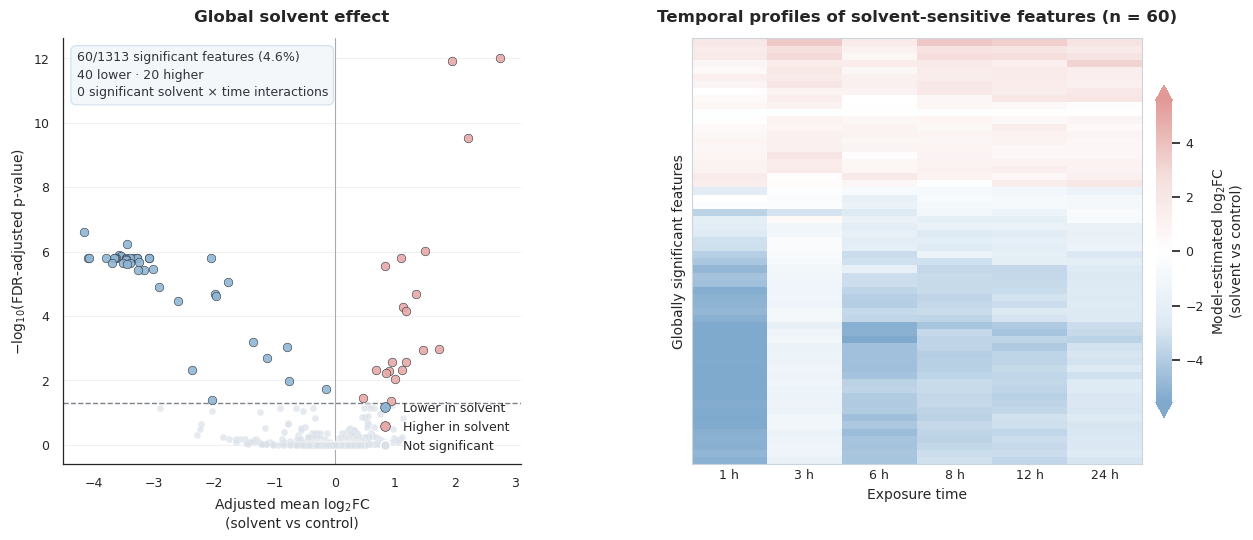

Figure saved to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\figures\statistical_analysis\solvent_effect


In [4]:
ALPHA = 0.05
TIME_ORDER = ["T1", "T3", "T6", "T8", "T12", "T24"]
TIME_LABELS = ["1 h", "3 h", "6 h", "8 h", "12 h", "24 h"]

RESULTS_FILE = (OUTPUT_TABLES / "solvent_effect" / "solvent_effect_results.xlsx")

FIGURE_DIR = (OUTPUT_FIGURES / "solvent_effect")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Publication-style colours
# ------------------------------------------------------------

COLOR_BACKGROUND = "#FFFFFF"
COLOR_NON_SIGNIFICANT = "#D9E0E8"
COLOR_HIGHER = "#E7AAA8"      
COLOR_LOWER = "#8FB6D5"        
COLOR_DARK = "#31343A"
COLOR_GRID = "#E8EBEF"

HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "pale_blue_white_salmon",
    ["#7FA9CD","#DCE9F3","#FFFFFF","#F4DEDC","#E29A97"])

# ------------------------------------------------------------
# Figure style
# ------------------------------------------------------------

sns.set_theme(style="white")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": COLOR_BACKGROUND,
    "axes.facecolor": COLOR_BACKGROUND,
    "savefig.facecolor": COLOR_BACKGROUND,})

# ------------------------------------------------------------
# Load results
# ------------------------------------------------------------

global_results = pd.read_excel(RESULTS_FILE, sheet_name="Global_solvent_effect")
time_contrasts = pd.read_excel(RESULTS_FILE, sheet_name="Contrasts_by_time")
global_results["Feature"] = (global_results["Feature"].astype(str))
time_contrasts["Feature"] = (time_contrasts["Feature"].astype(str))
global_results["q_Solvent_global_FDR"] = pd.to_numeric(global_results["q_Solvent_global_FDR"],errors="coerce")
global_results["q_Interaction_FDR"] = pd.to_numeric(global_results["q_Interaction_FDR"],errors="coerce")
global_results["log2FC_SOLVENT_vs_CONTROL"] = pd.to_numeric(global_results["log2FC_SOLVENT_vs_CONTROL"],errors="coerce")

# ------------------------------------------------------------
# Prepare volcano-plot data
# ------------------------------------------------------------

global_results["Significant"] = (global_results["q_Solvent_global_FDR"] < ALPHA)
global_results["Volcano_status"] = np.select([(global_results["Significant"] & (global_results["log2FC_SOLVENT_vs_CONTROL"] > 0)),
                                              (global_results["Significant"]& (global_results["log2FC_SOLVENT_vs_CONTROL"] < 0))],
                                             ["Higher in solvent", "Lower in solvent"], default="Not significant")

# Protect against log10(0)
global_results["minus_log10_q"] = -np.log10(global_results["q_Solvent_global_FDR"].clip(lower=np.finfo(float).tiny))
n_total = len(global_results)
n_significant = int(global_results["Significant"].sum())
n_higher = int((global_results["Volcano_status"]== "Higher in solvent").sum())
n_lower = int((global_results["Volcano_status"]== "Lower in solvent").sum())
n_interactions = int((global_results["q_Interaction_FDR"]< ALPHA).sum())

# ------------------------------------------------------------
# Prepare heatmap data
# ------------------------------------------------------------

significant_features = global_results.loc[global_results["Significant"],"Feature"].tolist()
heatmap_data = (time_contrasts.loc[time_contrasts["Feature"].isin(significant_features)
    ].pivot(index="Feature", 
            columns="Time",
            values="log2FC_SOLVENT_vs_CONTROL").reindex(columns=TIME_ORDER))

# Hierarchical clustering of temporal profiles
if len(heatmap_data) > 1:
    clustering_matrix = (heatmap_data.fillna(0).to_numpy())
    row_linkage = linkage(clustering_matrix, method="ward", metric="euclidean")
    row_order = leaves_list(row_linkage)
    heatmap_data = heatmap_data.iloc[row_order]

# Symmetrical colour scale around zero
absolute_values = np.abs(heatmap_data.to_numpy(dtype=float))
VMAX = np.nanpercentile(absolute_values, 97.5)
if not np.isfinite(VMAX) or VMAX == 0:
    VMAX = 1

# ------------------------------------------------------------
# Create combined figure
# ------------------------------------------------------------

fig = plt.figure(figsize=(13.2, 5.6))
grid = fig.add_gridspec(nrows=1, ncols=2, width_ratios=[1.05, 1.25], wspace=0.34)
ax_volcano = fig.add_subplot(grid[0, 0])
ax_heatmap = fig.add_subplot(grid[0, 1])

# ============================================================
# Global volcano plot
# ============================================================
plot_order = ["Not significant","Lower in solvent","Higher in solvent"]
plot_colours = {"Not significant": COLOR_NON_SIGNIFICANT,"Lower in solvent": COLOR_LOWER,"Higher in solvent": COLOR_HIGHER}
plot_sizes = {"Not significant": 25,"Lower in solvent": 38,"Higher in solvent": 38}

for status in plot_order:
    subset = global_results.loc[global_results["Volcano_status"] == status]
    ax_volcano.scatter(subset["log2FC_SOLVENT_vs_CONTROL"], subset["minus_log10_q"], 
                       s=plot_sizes[status], 
                       color=plot_colours[status],
                       edgecolor=("white" if status == "Not significant" else COLOR_DARK),
                       linewidth=(0.25 if status == "Not significant" else 0.45), 
                       alpha=(0.65 if status == "Not significant" else 0.90),
                       zorder=(2 if status == "Not significant" else 3))

# FDR threshold
fdr_threshold = -np.log10(ALPHA)
ax_volcano.axhline(fdr_threshold, color="#7D8289", linestyle="--", linewidth=1.0, zorder=1)
ax_volcano.axvline(0, color="#A7ABB0", linestyle="-", linewidth=0.8, zorder=1)

# Annotation box
summary_text = (
    f"{n_significant}/{n_total} significant features "
    f"({100 * n_significant / n_total:.1f}%)\n"
    f"{n_lower} lower · {n_higher} higher\n" 
    f"{n_interactions} significant solvent × time interactions")

ax_volcano.text(0.03, 0.97, summary_text, transform=ax_volcano.transAxes, ha="left", va="top", fontsize=9, color=COLOR_DARK, linespacing=1.45, 
                bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F4F7FA", "edgecolor": "#D4E2EE", "linewidth": 0.9})

ax_volcano.set_title("Global solvent effect",pad=12)
ax_volcano.set_xlabel("Adjusted mean log$_2$FC\n(solvent vs control)")
ax_volcano.set_ylabel("−log$_{10}$(FDR-adjusted p-value)")
ax_volcano.grid(axis="y", color=COLOR_GRID, linewidth=0.7, alpha=0.75)
ax_volcano.spines["top"].set_visible(False)
ax_volcano.spines["right"].set_visible(False)

# Custom legend
legend_handles = [
    Line2D( [0], [0], marker="o", linestyle="none", markerfacecolor=COLOR_LOWER, markeredgecolor=COLOR_DARK, markeredgewidth=0.45, markersize=7, label="Lower in solvent"),
    Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=COLOR_HIGHER, markeredgecolor=COLOR_DARK, markeredgewidth=0.45, markersize=7, label="Higher in solvent"),
    Line2D([0], [0], marker="o",linestyle="none", markerfacecolor=COLOR_NON_SIGNIFICANT, markeredgecolor="white", markersize=7, label="Not significant")]

ax_volcano.legend(handles=legend_handles,frameon=False,loc="lower right",handletextpad=0.5)

# ============================================================
# Temporal heatmap
# ============================================================
heatmap = sns.heatmap(
    heatmap_data,
    ax=ax_heatmap,
    cmap=HEATMAP_CMAP,
    center=0,
    vmin=-VMAX,
    vmax=VMAX,
    yticklabels=False,
    xticklabels=TIME_LABELS,
    linewidths=0,
    rasterized=True,
    cbar_kws={
        "label": "Model-estimated log$_2$FC\n(solvent vs control)",
        "shrink": 0.78,
        "pad": 0.025,
        "extend": "both"})

ax_heatmap.set_title(f"Temporal profiles of solvent-sensitive features (n = {n_significant})", pad=12)
ax_heatmap.set_xlabel("Exposure time")
ax_heatmap.set_ylabel("Globally significant features")
ax_heatmap.tick_params(axis="x",rotation=0,length=0)
ax_heatmap.tick_params(axis="y",length=0)

# Light frame around heatmap
for spine in ax_heatmap.spines.values():
    spine.set_visible(True)
    spine.set_color("#CCD5DE")
    spine.set_linewidth(0.8)

# ------------------------------------------------------------
# Final layout and export
# ------------------------------------------------------------

fig.subplots_adjust(left=0.07, right=0.96, bottom=0.14, top=0.90)
OUTPUT_BASENAME = (FIGURE_DIR / "solvent_effect_global_volcano_temporal_heatmap")

fig.savefig(OUTPUT_BASENAME.with_suffix(".png"), dpi=600, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {FIGURE_DIR}")

# 2. Global psychostimulant-associated metabolic response

## 2.1 Blocked two-way ANOVA
A blocked two-factor linear model was fitted to each metabolic feature using log2-transformed intensities. The model included treatment, exposure time,
their interaction, and experiment as a blocking factor.
The global psychostimulant effect was evaluated using a planned contrast comparing the equally weighted mean response to METH, MDMA, 3-MMC, and α-PHP with the solvent control. Candidate features were selected at the early and late exposure times using a p-value threshold of 0.05.

In [6]:
INPUT_SHEET = "final_cleaned_data"
SOLVENT_LABEL = "S"
STIM_DRUGS = ["Meth", "MDMA", "3MMC", "alphaPHP"]
TREATMENT_ORDER = [SOLVENT_LABEL] + STIM_DRUGS
TIME_ORDER = ["T1", "T3", "T6", "T8", "T12", "T24"]

# Times prioritized for exploratory feature selection
SELECTION_TIMES = ["T1", "T24"]

ALPHA = 0.05

OUTPUT_DIR = OUTPUT_TABLES / "global_signature" / "anova"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = (OUTPUT_DIR / "blocked_ANOVA_STIM_vs_solvent_T1_T24.xlsx")
# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def fdr_bh(p_values):
    """
    Benjamini–Hochberg correction.
    Adjusted p-values are reported for transparency but are not
    used for exploratory candidate selection.
    """
    p_values = pd.to_numeric(pd.Series(p_values), errors="coerce")
    q_values = np.full(len(p_values), np.nan)
    valid = p_values.notna()
    if valid.any():
        q_values[valid] = multipletests(p_values.loc[valid], method="fdr_bh")[1]
    return q_values

def design_vector(model, treatment, time, experiment):
    """Return the model-design vector for one condition."""
    new_data = pd.DataFrame({"Treatment": [treatment], "Time": [time], "Experiment": [experiment]})
    design_matrix = build_design_matrices([model.model.data.design_info], new_data, return_type="dataframe")[0]
    return design_matrix.iloc[0].to_numpy()

def stim_vs_solvent_vector(model, time, experiment):
    """
    Return the equal-weighted contrast:
        mean(Meth, MDMA, 3MMC, alphaPHP) - solvent
    for one exposure time.
    """
    stim_vectors = np.vstack([design_vector(model=model, treatment=drug, time=time, experiment=experiment) for drug in STIM_DRUGS])
    solvent_vector = design_vector(model=model, treatment=SOLVENT_LABEL, time=time, experiment=experiment)
    return stim_vectors.mean(axis=0) - solvent_vector

def contrast_statistics(model, contrast_vector):
    """Estimate a one-degree-of-freedom model contrast."""
    test = model.t_test(np.asarray(contrast_vector).reshape(1, -1))
    confidence_interval = test.conf_int(alpha=0.05)
    log2fc = float(np.asarray(test.effect).squeeze())
    return {
        "log2FC": log2fc,
        "fold_change": float(2 ** log2fc),
        "CI95_low": float(confidence_interval[0, 0]),
        "CI95_high": float(confidence_interval[0, 1]),
        "t_value": float(np.asarray(test.tvalue).squeeze()),
        "p_value": float(np.asarray(test.pvalue).squeeze())}

# ------------------------------------------------------------
# Data import and metadata formatting
# ------------------------------------------------------------

df = pd.read_excel(INPUT_FILE, sheet_name=INPUT_SHEET)
df.columns = [str(column) for column in df.columns]

# Compatibility with the metadata names used in older files
rename_map = {}
if "sample_type" not in df.columns and "type" in df.columns:
    rename_map["type"] = "sample_type"
    
if "experiment" not in df.columns and "exp" in df.columns:
    rename_map["exp"] = "experiment"

if "sample_id" not in df.columns and "raw_name" in df.columns:
    rename_map["raw_name"] = "sample_id"

df = df.rename(columns=rename_map)

required_columns = {"sample_id", "sample_type", "experiment", "drug", "time"}
missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError("Missing required metadata columns: " f"{sorted(missing_columns)}")

# ------------------------------------------------------------
# Sample selection
# ------------------------------------------------------------

cell_df = df.loc[df["sample_type"].astype(str).eq("CELL")].copy()

# Exclude technical reinjections
reinjection_mask = (cell_df["sample_id"].astype(str).str.contains("_INJ", case=False, na=False))
if reinjection_mask.any():
    print("Technical reinjections excluded: " f"{int(reinjection_mask.sum())}")
    cell_df = cell_df.loc[ ~reinjection_mask].copy()

# Standardized metadata
cell_df["Treatment"] = (cell_df["drug"].astype(str))
cell_df["Time"] = (cell_df["time"].astype(str).str.extract("(T\d+)", expand=False))
cell_df["Experiment"] = (cell_df["experiment"].astype(str))

# MZmine feature identifiers
feature_columns = [column for column in cell_df.columns if re.fullmatch(r"\d+", column)]
if not feature_columns:
    raise ValueError("No numeric MZmine feature identifiers were found.")
cell_df[feature_columns] = (cell_df[feature_columns].apply( pd.to_numeric, errors="coerce"))

# Keep solvent and psychostimulant samples
analysis_df = cell_df.loc[cell_df["Treatment"].isin(TREATMENT_ORDER) & cell_df["Time"].isin(TIME_ORDER)].copy()
analysis_df["Treatment"] = pd.Categorical(analysis_df["Treatment"], categories=TREATMENT_ORDER, ordered=True)
analysis_df["Time"] = pd.Categorical(analysis_df["Time"], categories=TIME_ORDER, ordered=True)

# ------------------------------------------------------------
# Zero replacement and log2 transformation
# ------------------------------------------------------------
zero_replacements = (cell_df[feature_columns].where(cell_df[feature_columns] > 0).min(axis=0).div(2))
intensity_matrix = (analysis_df[feature_columns].apply(pd.to_numeric, errors="coerce").mask(lambda matrix: matrix <= 0).fillna(zero_replacements))

# Retain fully defined, positive and non-constant features
valid_features = (intensity_matrix.notna().all(axis=0) & intensity_matrix.gt(0).all(axis=0) & intensity_matrix.nunique(dropna=False).gt(1))
feature_columns = list(intensity_matrix.columns[valid_features])
analysis_df[feature_columns] = np.log2(intensity_matrix[feature_columns])

# ------------------------------------------------------------
# Experimental-design summary
# ------------------------------------------------------------

design_counts = (analysis_df.groupby(["Time", "Treatment"],observed=True).size().reset_index(name="n"))
print(f"Samples included: {analysis_df.shape[0]}")
print(f"Features tested: {len(feature_columns)}")
print("Experiments: " f"{analysis_df['Experiment'].nunique()}")
print("\nDesign counts:")
print(design_counts.to_string(index=False))

# ------------------------------------------------------------
# Feature-wise blocked linear models
# ------------------------------------------------------------
global_rows = []
contrast_rows = []
error_rows = []
experiment_reference = sorted(analysis_df["Experiment"].unique())[0]

for feature in feature_columns:
    model_data = (analysis_df[["Treatment", "Time", "Experiment", feature]].dropna().rename(columns={feature: "y"}))
    try:
        model = smf.ols(formula=("y ~ C(Treatment, Sum) * C(Time, Sum) + C(Experiment, Sum)"), data=model_data).fit()
        anova_table = anova_lm(model, typ=3)
        treatment_term = "C(Treatment, Sum)"
        time_term = "C(Time, Sum)"
        interaction_term = ("C(Treatment, Sum):C(Time, Sum)")

        # Equal-weighted STIM-versus-solvent contrast
        # estimated separately at each exposure time
        time_vectors = {time: stim_vs_solvent_vector(model=model, time=time, experiment=experiment_reference) for time in TIME_ORDER}
        # Average STIM-versus-solvent effect across all times
        global_vector = np.mean(np.vstack(list(time_vectors.values())), axis=0)
        global_effect = contrast_statistics(model=model, contrast_vector=global_vector)

        # Does the STIM-versus-solvent contrast vary over time?
        reference_vector = time_vectors[TIME_ORDER[0]]
        interaction_matrix = np.vstack([time_vectors[time] - reference_vector for time in TIME_ORDER[1:]])
        interaction_test = model.f_test( interaction_matrix)
        
        global_rows.append({"Feature": str(feature), "n_samples": len(model_data),
                            "log2FC_STIM_vs_SOLVENT_global": global_effect["log2FC"],
                            "fold_change_STIM_vs_SOLVENT_global": global_effect["fold_change"], 
                            "CI95_low_global": global_effect["CI95_low"], 
                            "CI95_high_global": global_effect["CI95_high"],
                            "t_global": global_effect["t_value"],
                            "p_STIM_vs_SOLVENT_global": global_effect["p_value"], 
                            "F_STIM_vs_SOLVENT_x_Time": float(np.asarray(interaction_test.fvalue).squeeze()),
                            "p_STIM_vs_SOLVENT_x_Time": float(np.asarray(interaction_test.pvalue).squeeze()),
                            "F_Treatment_omnibus": anova_table.loc[treatment_term, "F"],
                            "p_Treatment_omnibus": anova_table.loc[treatment_term, "PR(>F)"], 
                            "F_Time": anova_table.loc[time_term, "F"],
                            "p_Time": anova_table.loc[time_term, "PR(>F)"],
                            "F_Treatment_x_Time_omnibus": anova_table.loc[interaction_term, "F"],
                            "p_Treatment_x_Time_omnibus": anova_table.loc[interaction_term, "PR(>F)"],  
                            "R2_model": model.rsquared,
                            "Adjusted_R2_model": model.rsquared_adj})

        # Time-specific contrasts
        for time in TIME_ORDER:
            effect = contrast_statistics(model=model,contrast_vector=time_vectors[time])
            contrast_rows.append({"Feature": str(feature), 
                                  "Time": time, 
                                  "log2FC_STIM_vs_SOLVENT": effect["log2FC"],
                                  "fold_change_STIM_vs_SOLVENT": effect["fold_change"],
                                  "CI95_low": effect["CI95_low"],
                                  "CI95_high": effect["CI95_high"],
                                  "t_value": effect["t_value"],
                                  "p_value": effect["p_value"]})
    except Exception as error:
        error_rows.append({"Feature": str(feature),"Error": str(error)[:500]})

global_results = pd.DataFrame(global_rows)
time_contrasts = pd.DataFrame(contrast_rows)
model_errors = pd.DataFrame(error_rows)

if global_results.empty:
    raise ValueError("No feature-level model could be fitted.")

# ------------------------------------------------------------
# FDR values retained for transparency only
# ------------------------------------------------------------

global_results["q_STIM_vs_SOLVENT_global_FDR"] = fdr_bh(global_results["p_STIM_vs_SOLVENT_global"])
global_results["q_STIM_vs_SOLVENT_x_Time_FDR"] = fdr_bh(global_results["p_STIM_vs_SOLVENT_x_Time"])
global_results["q_Time_FDR"] = fdr_bh(global_results["p_Time"])

time_contrasts["q_value_FDR"] = np.nan
for time in TIME_ORDER:
    time_mask = (time_contrasts["Time"].eq(time))
    time_contrasts.loc[time_mask, "q_value_FDR",] = fdr_bh(time_contrasts.loc[time_mask, "p_value",])
    
# ------------------------------------------------------------
# Candidate selection
# ------------------------------------------------------------

time_contrasts["Candidate"] = (time_contrasts["p_value"] < ALPHA)
time_contrasts["Direction"] = np.select([time_contrasts["log2FC_STIM_vs_SOLVENT"] > 0,
                                         time_contrasts["log2FC_STIM_vs_SOLVENT"] < 0,],
                                        ["Higher in STIM","Lower in STIM"],
                                        default="No change")

# Candidate tables at T1 and T24
candidates_by_time = {}
for time in SELECTION_TIMES:
    candidates = (time_contrasts.loc[time_contrasts["Time"].eq(time) & 
        time_contrasts["Candidate"]].copy().sort_values(["p_value", "log2FC_STIM_vs_SOLVENT"], ascending=[True, False]))
    candidates_by_time[time] = candidates

t1_candidates = candidates_by_time["T1"]
t24_candidates = candidates_by_time["T24"]

# ------------------------------------------------------------
# Union and intersection of T1 and T24 candidates
# ------------------------------------------------------------

t1_features = set(t1_candidates["Feature"])
t24_features = set(t24_candidates["Feature"])
union_features = (t1_features | t24_features)
shared_features = (t1_features & t24_features)

selection_summary = pd.DataFrame({"Feature": sorted(union_features),})
selection_summary["Selected_T1"] = (selection_summary["Feature"].isin(t1_features))
selection_summary["Selected_T24"] = (selection_summary["Feature"].isin(t24_features))
selection_summary["Selection_status"] = np.select([(selection_summary["Selected_T1"] & selection_summary["Selected_T24"]),
                                                    selection_summary["Selected_T1"],
                                                    selection_summary["Selected_T24"]],
                                                    ["T1 and T24", "T1 only", "T24 only"],
                                                    default="Not selected")
# Add the T1 and T24 statistics
selection_statistics = (time_contrasts.loc[time_contrasts["Time"].isin(SELECTION_TIMES),
    [ "Feature", "Time", "log2FC_STIM_vs_SOLVENT", "fold_change_STIM_vs_SOLVENT", 
      "CI95_low", "CI95_high", "t_value", "p_value", "q_value_FDR", "Direction"]].pivot(index="Feature", columns="Time"))

selection_statistics.columns = [f"{metric}_{time}" for metric, time in selection_statistics.columns]
selection_statistics = (selection_statistics.reset_index())
selection_summary = selection_summary.merge(selection_statistics, on="Feature", how="left")

# Directional consistency between T1 and T24
selection_summary["Same_direction_T1_T24"] = np.where((selection_summary["Selected_T1"] & selection_summary["Selected_T24"]),
                                                      (np.sign(selection_summary["log2FC_STIM_vs_SOLVENT_T1"]) == 
                                                       np.sign(selection_summary["log2FC_STIM_vs_SOLVENT_T24"])), pd.NA)

# ------------------------------------------------------------
# Feature-level table across all six times
# ------------------------------------------------------------

time_wide = (time_contrasts[["Feature", "Time", "log2FC_STIM_vs_SOLVENT", "fold_change_STIM_vs_SOLVENT",
                            "CI95_low", "CI95_high", "p_value", "q_value_FDR", "Candidate", "Direction"]].pivot(index="Feature", columns="Time"))

time_wide.columns = [f"{metric}_{time}" for metric, time in time_wide.columns]
time_wide = time_wide.reset_index()

feature_summary = global_results.merge(time_wide, on="Feature", how="left")
feature_summary["Selected_T1"] = (feature_summary["Feature"].isin(t1_features))
feature_summary["Selected_T24"] = (feature_summary["Feature"].isin(t24_features))
feature_summary["Selected_either_T1_or_T24"] = (feature_summary["Selected_T1"] | feature_summary["Selected_T24"])
feature_summary["Selected_both_T1_and_T24"] = (feature_summary["Selected_T1"] & feature_summary["Selected_T24"])

# ------------------------------------------------------------
# Add solvent-effect annotation, when available
# ------------------------------------------------------------

solvent_results_file = (OUTPUT_TABLES / "solvent_effect" / "solvent_effect_results.xlsx")

if solvent_results_file.exists():
    solvent_annotation = pd.read_excel(solvent_results_file, sheet_name="Feature_annotation")
    solvent_annotation["Feature"] = (solvent_annotation["Feature"].astype(str))
    annotation_columns = [column for column in ["Feature", "Solvent_sensitive", "Solvent_status", "Solvent_direction"]
                          if column in solvent_annotation.columns]
    feature_summary = feature_summary.merge(solvent_annotation[annotation_columns], on="Feature", how="left")
    selection_summary = selection_summary.merge(solvent_annotation[annotation_columns], on="Feature", how="left")

# ------------------------------------------------------------
# Summary counts
# ------------------------------------------------------------

summary_rows = [{"Metric": "Features tested",
                 "Value": len(global_results)},
                {"Metric": ("Global STIM vs solvent effect (p < 0.05)"),
                 "Value": int((global_results["p_STIM_vs_SOLVENT_global"] < ALPHA).sum())},
                {"Metric": ("STIM vs solvent × time interaction (p < 0.05)"),
                 "Value": int((global_results["p_STIM_vs_SOLVENT_x_Time"] < ALPHA).sum())},
                {"Metric": ("Candidates at T1 (p < 0.05)"),
                 "Value": len(t1_features)},
                {"Metric": ("Candidates at T24 (p < 0.05)"),
                 "Value": len(t24_features)},
                {"Metric": ("Union of T1 and T24 candidates"),
                 "Value": len(union_features)}, 
                {"Metric": ("Candidates shared by T1 and T24"), 
                 "Value": len(shared_features)}]

# All time-specific counts retained descriptively
for time in TIME_ORDER:
    n_candidates = int(time_contrasts.loc[time_contrasts["Time"].eq(time), "Candidate"].sum())
    summary_rows.append({"Metric": (f"STIM vs solvent candidates at {time}"), "Value": n_candidates})

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Sorting
# ------------------------------------------------------------

global_results = global_results.sort_values("p_STIM_vs_SOLVENT_global", na_position="last")
time_contrasts = time_contrasts.sort_values(["Time", "p_value"], na_position="last")
feature_summary = feature_summary.sort_values(
    ["Selected_both_T1_and_T24", "Selected_either_T1_or_T24", "p_value_T24", "p_value_T1"], ascending=[False, False, True, True], na_position="last")
selection_summary = (selection_summary.sort_values(
    ["Selected_T1", "Selected_T24", "p_value_T24", "p_value_T1"], ascending=[False, False, True, True], na_position="last"))


# ------------------------------------------------------------
# Export
# ------------------------------------------------------------

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    design_counts.to_excel(writer, sheet_name="Design_counts", index=False)
    summary_df.to_excel(writer, sheet_name="Summary", index=False)
    global_results.to_excel(writer, sheet_name="Global_results", index=False)
    time_contrasts.to_excel(writer, sheet_name="Contrasts_all_times", index=False)
    feature_summary.to_excel(writer, sheet_name="Feature_summary", index=False)
    t1_candidates.to_excel(writer, sheet_name="Candidates_T1", index=False)
    t24_candidates.to_excel(writer, sheet_name="Candidates_T24", index=False)
    selection_summary.to_excel(writer, sheet_name="Candidates_union", index=False)
    selection_summary.loc[selection_summary["Selection_status"].eq("T1 and T24")].to_excel(writer, sheet_name="Candidates_shared", index=False)

    if not model_errors.empty:
        model_errors.to_excel(writer, sheet_name="Model_errors", index=False)


# ------------------------------------------------------------
# Console output
# ------------------------------------------------------------

print("\nBlocked two-factor analysis completed.")
print(summary_df.to_string(index=False))
print(f"\nExploratory selection is based on p < {ALPHA}")
print(f"T1 candidates: {len(t1_features)}")
print(f"T24 candidates: {len(t24_features)}")
print(f"T1/T24 union: {len(union_features)}")
print(f"Shared at T1 and T24:{len(shared_features)}")
print(f"\nResults saved to: {OUTPUT_FILE}")

Samples included: 142
Features tested: 1313
Experiments: 5

Design counts:
Time Treatment  n
  T1         S  5
  T1      Meth  5
  T1      MDMA  5
  T1      3MMC  5
  T1  alphaPHP  4
  T3         S  5
  T3      Meth  5
  T3      MDMA  5
  T3      3MMC  5
  T3  alphaPHP  4
  T6         S  4
  T6      Meth  5
  T6      MDMA  5
  T6      3MMC  5
  T6  alphaPHP  4
  T8         S  5
  T8      Meth  5
  T8      MDMA  5
  T8      3MMC  5
  T8  alphaPHP  4
 T12         S  5
 T12      Meth  5
 T12      MDMA  4
 T12      3MMC  5
 T12  alphaPHP  4
 T24         S  5
 T24      Meth  5
 T24      MDMA  5
 T24      3MMC  5
 T24  alphaPHP  4

Blocked two-factor analysis completed.
                                       Metric  Value
                              Features tested   1313
     Global STIM vs solvent effect (p < 0.05)    257
STIM vs solvent × time interaction (p < 0.05)     86
                  Candidates at T1 (p < 0.05)    110
                 Candidates at T24 (p < 0.05)    133
         

## 2.2. ASCA+ model 
ASCA+ was used to investigate coordinated metabolic variation associated with
psychostimulant exposure and exposure time. Feature intensities were
log2-transformed, mean-centered, and Pareto-scaled before analysis.

A multivariate general linear model included experiment as a blocking factor,
time, an equal-weighted contrast comparing the four psychostimulants with the
solvent control, and contrasts describing heterogeneity among the four drugs.
Interactions with exposure time were also included.

The significance of the predefined multivariate effects was assessed by
Freedman–Lane residual permutation tests restricted within experimental blocks.
Feature contributions at T1 and T24 were calculated from the model-estimated
STIM-versus-solvent contrasts. No contribution threshold was applied at this
stage.

### 2.2.1 Global ASCA+ model and permutation testing

This analysis applies an ASCA+ model to decompose the metabolic variation into experiment, global psychostimulant, drug-specific, time, and interaction effects. Effect sizes are estimated using Type III sums of squares, while their statistical significance is assessed through 4,999 restricted permutations performed within experimental blocks.

In [7]:
INPUT_SHEET = "final_cleaned_data"
SOLVENT_LABEL = "S"
STIM_DRUGS = ["Meth", "MDMA", "3MMC", "alphaPHP"]
TREATMENT_ORDER = [SOLVENT_LABEL, *STIM_DRUGS]
TIME_ORDER = ["T1", "T3", "T6", "T8", "T12", "T24"]
SELECTION_TIMES = ["T1", "T24"]

N_COMPONENTS = 3
N_PERMUTATIONS = 4999
RANDOM_STATE = 42
OUTPUT_DIR = (OUTPUT_TABLES / "global_signature" / "asca_plus")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = (OUTPUT_DIR / "ASCA_plus_STIM_vs_solvent.xlsx")

# ------------------------------------------------------------
# Treatment contrasts
# ------------------------------------------------------------

TREATMENT_CONTRASTS = {"Global_STIM": {SOLVENT_LABEL: -1.0, "Meth": 0.25, "MDMA": 0.25, "3MMC": 0.25, "alphaPHP": 0.25}, "Meth_vs_MDMA": {SOLVENT_LABEL: 0.0, "Meth": 1.0, "MDMA": -1.0, "3MMC": 0.0, "alphaPHP": 0.0}, "Amphetamine_vs_3MMC": {SOLVENT_LABEL: 0.0, "Meth": 0.5, "MDMA": 0.5, "3MMC": -1.0, "alphaPHP": 0.0}, "First3_vs_alphaPHP": {SOLVENT_LABEL: 0.0, "Meth": 1 / 3, "MDMA": 1 / 3, "3MMC": 1 / 3, "alphaPHP": -1.0}}

# ============================================================
# Helper functions
# ============================================================

def sum_code(values, levels, prefix):
    values = (pd.Series(values).astype(str).to_numpy())
    reference_level = levels[-1]
    encoded = {}
    for level in levels[:-1]:
        encoded[f"{prefix}[{level}]"] = np.where(values == level, 1.0, np.where(values == reference_level, -1.0, 0.0))
    return pd.DataFrame(encoded)

def build_design_matrix(metadata, experiment_order):
    """
    Construct the ASCA+ general linear model matrix.
    Model:
        Intercept
        + Experiment
        + Global_STIM
        + Within_STIM
        + Time
        + Global_STIM × Time
        + Within_STIM × Time
    """
    metadata = (metadata.reset_index(drop=True).copy())
    design = pd.DataFrame(index=metadata.index)
    blocks = {}
    
    # Intercept
    design["Intercept"] = 1.0
    blocks["Intercept"] = ["Intercept"]
    
    # Experimental block
    experiment_terms = sum_code(values=metadata["Experiment"], levels=experiment_order, prefix="Experiment")
    design = pd.concat([design, experiment_terms], axis=1)
    blocks["Experiment"] = list(experiment_terms.columns)
    
    # Treatment contrasts
    for contrast_name, coding in (TREATMENT_CONTRASTS.items()):
        design[contrast_name] = (metadata["Treatment"].map(coding).astype(float))
    blocks["Global_STIM"] = ["Global_STIM"]
    within_stim_terms = ["Meth_vs_MDMA", "Amphetamine_vs_3MMC", "First3_vs_alphaPHP"]
    blocks["Within_STIM"] = (within_stim_terms)
    
    # Time effect
    time_terms = sum_code(values=metadata["Time"], levels=TIME_ORDER, prefix="Time")
    design = pd.concat([design, time_terms], axis=1)
    blocks["Time"] = list(time_terms.columns)
    
    # Global STIM × Time
    stim_time_terms = []
    for time_column in time_terms.columns:
        column_name = (f"Global_STIM:{time_column}")
        design[column_name] = (design["Global_STIM"] * design[time_column])
        stim_time_terms.append(column_name)
    blocks["Global_STIM_x_Time"] = (stim_time_terms)
    
    # Within-STIM heterogeneity × Time
    within_stim_time_terms = []
    for treatment_column in within_stim_terms:
        for time_column in time_terms.columns:
            column_name = (f"{treatment_column}: {time_column}")
            design[column_name] = (design[treatment_column] * design[time_column])
            within_stim_time_terms.append(column_name)
    blocks["Within_STIM_x_Time"] = (within_stim_time_terms)
    return design, blocks

def design_row(treatment, time, experiment, experiment_order, design_columns):
    """
    Construct one row of the ASCA+ design matrix for a
    defined treatment, time and experiment.
    """
    metadata = pd.DataFrame({"Treatment": [treatment], "Time": [time], "Experiment": [experiment]})
    row, _ = build_design_matrix(metadata=metadata, experiment_order=experiment_order)
    return (row.reindex(columns=design_columns, fill_value=0.0).iloc[0].to_numpy(dtype=float))

def fit_multivariate_model(design, response,):
    """
    Fit the multivariate general linear model:
        Y = X B + E
    """
    design = np.asarray(design, dtype=float)
    response = np.asarray(response, dtype=float)
    coefficients = (np.linalg.pinv(design) @ response)
    fitted = (design @ coefficients)
    residuals = (response - fitted)
    return (coefficients, fitted, residuals)

def sum_of_squares(matrix):
    """
    Return the squared Frobenius norm of a matrix.
    """
    matrix = np.asarray(matrix, dtype=float)
    return float(np.sum(matrix ** 2))

def run_pca(matrix, n_components=3):
    """
    Perform PCA using singular value decomposition.
    The matrix is mean-centered before decomposition.
    """
    matrix = np.asarray(matrix, dtype=float)
    centered = (matrix - np.mean(matrix, axis=0, keepdims=True))
    u, singular_values, vt = np.linalg.svd(centered, full_matrices=False)
    eigenvalues = (singular_values ** 2)
    if eigenvalues.size == 0:
        return (np.empty((matrix.shape[0], 0)), np.empty((matrix.shape[1], 0)), np.array([]))
    maximum_eigenvalue = (eigenvalues.max())
    tolerance = (np.finfo(float).eps * max(centered.shape) * maximum_eigenvalue)
    n_available = int((eigenvalues > tolerance).sum())
    n_keep = min(n_components, n_available)
    if n_keep == 0:
        return (np.empty((matrix.shape[0], 0)), np.empty((matrix.shape[1], 0)), np.array([]))
    scores = (u[:, :n_keep] * singular_values[:n_keep])
    loadings = (vt[:n_keep, :].T)
    explained_variance = (eigenvalues[:n_keep] / eigenvalues.sum())
    return (scores, loadings, explained_variance)

def restricted_permutation_indices(block_values, rng):
    """
    Permute observations only within experimental blocks.
    """
    block_values = np.asarray(block_values)
    permutation = np.arange(len(block_values))
    for block in pd.unique(block_values):
        positions = np.where(block_values == block)[0]
        permutation[positions] = (rng.permutation(positions))
    return permutation

def freedman_lane_test(design, response, tested_columns, design_columns, permutation_blocks, n_permutations, seed):
    """
    Freedman–Lane residual permutation test.
    The tested effect is removed from the reduced model.
    Reduced-model residuals are then permuted within
    experimental blocks.
    """
    design = np.asarray(design, dtype=float)
    response = np.asarray(response, dtype=float)
    tested_indices = [design_columns.index(column) for column in tested_columns]
    reduced_indices = [index for index, column in enumerate(design_columns) if column not in tested_columns]
    reduced_design = (design[:, reduced_indices])
    reduced_hat_matrix = (reduced_design  @ np.linalg.pinv(reduced_design))
    
    # Subspace uniquely attributable to the tested effect
    tested_residualized = (np.eye(design.shape[0]) - reduced_hat_matrix) @ design[:, tested_indices]
    u, singular_values, _ = np.linalg.svd(tested_residualized, full_matrices=False)
    maximum_singular_value = (singular_values.max() if singular_values.size > 0 else 0.0)
    tolerance = (max(tested_residualized.shape) * np.finfo(float).eps * maximum_singular_value)
    effect_rank = int((singular_values > tolerance).sum())
    
    if effect_rank == 0:
        return {"df_effect": 0, "SS_observed": np.nan, "p_permutation": np.nan,}
    
    effect_basis = (u[:, :effect_rank])
    fitted_reduced = (reduced_hat_matrix @ response)
    residuals_reduced = (response - fitted_reduced)
    observed_statistic = sum_of_squares(effect_basis.T @ response)
    rng = np.random.default_rng(seed)
    permuted_statistics = np.empty(n_permutations, dtype=float,)
    fixed_component = (effect_basis.T @ fitted_reduced)
    
    for permutation_index in range(n_permutations):
        row_permutation = (restricted_permutation_indices(block_values=permutation_blocks, rng=rng,))
        permuted_response_projection = (fixed_component + effect_basis.T @ residuals_reduced[row_permutation,:])
        permuted_statistics[permutation_index] = sum_of_squares(permuted_response_projection)
    permutation_p_value = (1 + np.sum(permuted_statistics >= observed_statistic)) / (n_permutations + 1)
    return {"df_effect": effect_rank, "SS_observed": observed_statistic, "p_permutation": float(permutation_p_value),}

def type3_variance_decomposition(design, response, design_blocks, effect_matrices, effect_order,):
    """
    Compute ASCA+ Type III partial sums of squares.
    For each effect f:
        SS_TypeIII(f) = SSE_reduced_without_f - SSE_full
    Two percentages are returned:
    TypeIII_pct_centered_total:
        Exact Type III formulation relative to ||Y - M0||².
    Normalized_pct_sum100:
        Alternative normalized formulation for which effects
        and residuals sum to 100%.
    """
    if not isinstance(design, pd.DataFrame,):
        raise TypeError("'design' must be a pandas DataFrame.")
    
    X_full = design.to_numpy(dtype=float)
    Y = np.asarray(response, dtype=float,)
    design_columns = list(design.columns)
    
    # Full model
    coefficients_full, _, residuals_full = (fit_multivariate_model(design=X_full, response=Y,))
    sse_full = sum_of_squares(residuals_full)
    rank_full = np.linalg.matrix_rank(X_full)
    
    # Intercept effect matrix M0
    intercept_indices = [design_columns.index(column) for column in design_blocks["Intercept"]]
    intercept_matrix = (X_full[:, intercept_indices] @ coefficients_full[intercept_indices,:])
    
    # Denominator from equations 24 and 25:
    # ||Y - M0||²
    centered_total_ss = sum_of_squares(Y - intercept_matrix)
    
    if centered_total_ss <= 0:
        raise ValueError("Centered total sum of squares " "must be positive.")
    rows = []
    
    # Reduced model for each effect
    for effect_name in effect_order:
        effect_columns = set(design_blocks[effect_name])
        retained_indices = [index for index, column in enumerate(design_columns) if column not in effect_columns]
        reduced_design = (X_full[:, retained_indices])
        _, _, residuals_reduced = (fit_multivariate_model(design=reduced_design, response=Y,))
        sse_reduced = sum_of_squares(residuals_reduced)
        rank_reduced = np.linalg.matrix_rank(reduced_design)
        type3_partial_ss = (sse_reduced - sse_full)
        
        # Protect against negligible negative values generated by numerical precision
        numerical_tolerance = (1e-10 * max(sse_reduced, sse_full, 1.0,))
        
        if type3_partial_ss < -numerical_tolerance:
            raise ValueError("Negative Type III sum of squares for " f"{effect_name}: {type3_partial_ss}")
        type3_partial_ss = max(type3_partial_ss, 0.0,)
        
        # Geometrical norm of the ASCA+ effect matrix
        effect_matrix_ss = sum_of_squares(effect_matrices[effect_name])
        partial_r2 = (type3_partial_ss / (type3_partial_ss + sse_full) if (type3_partial_ss + sse_full) > 0 else np.nan)
        rows.append({"Effect": effect_name, "df_effect": rank_full - rank_reduced, "SSE_reduced_without_effect": sse_reduced, "SSE_full": sse_full, "TypeIII_partial_SS": type3_partial_ss, "TypeIII_pct_centered_total": 100 * type3_partial_ss / centered_total_ss, "Partial_R2": partial_r2, "Effect_matrix_SS": effect_matrix_ss, "Effect_matrix_pct_centered_total": 100 * effect_matrix_ss / centered_total_ss,})
    summary = pd.DataFrame(rows)
    
    # Normalized formulation:
    # effects + residuals sum to 100%
    normalized_denominator = (summary["TypeIII_partial_SS"].sum() + sse_full)
    summary["Normalized_pct_sum100"] = (100 * summary["TypeIII_partial_SS"] / normalized_denominator)
    residual_row = pd.DataFrame([{"Effect": "Residual", "df_effect": Y.shape[0] - rank_full, "SSE_reduced_without_effect": np.nan, "SSE_full": sse_full, "TypeIII_partial_SS": np.nan, "TypeIII_pct_centered_total": 100 * sse_full / centered_total_ss, "Partial_R2": np.nan, "Effect_matrix_SS": sse_full, "Effect_matrix_pct_centered_total": 100 * sse_full / centered_total_ss, "Normalized_pct_sum100": 100 * sse_full / normalized_denominator,}])
    summary = pd.concat([summary, residual_row,], ignore_index=True,)
    return (summary, centered_total_ss, sse_full,)

# ============================================================
# Data import and metadata formatting
# ============================================================

df = pd.read_excel(INPUT_FILE, sheet_name=INPUT_SHEET,)
df.columns = [str(column) for column in df.columns]

# Compatibility with older metadata names
rename_map = {}
if ("sample_type" not in df.columns and "type" in df.columns):
    rename_map["type"] = "sample_type"

if ("experiment" not in df.columns and "exp" in df.columns):
    rename_map["exp"] = "experiment"

if ("sample_id" not in df.columns and "raw_name" in df.columns):
    rename_map["raw_name"] = "sample_id"

df = df.rename(columns=rename_map)
required_columns = {"sample_id", "sample_type", "experiment", "drug", "time",}
missing_columns = (required_columns.difference(df.columns))

if missing_columns:
    raise ValueError("Missing required metadata columns: " f"{sorted(missing_columns)}")

# ============================================================
# Sample selection
# ============================================================
cell_df = df.loc[df["sample_type"].astype(str).eq("CELL")].copy()

# Remove technical reinjections
reinjection_mask = (cell_df["sample_id"].astype(str).str.contains("_INJ", case=False, na=False,))

if reinjection_mask.any():
    print("Technical reinjections excluded: " f"{int(reinjection_mask.sum())}")
    cell_df = cell_df.loc[~reinjection_mask].copy()

cell_df["Treatment"] = (cell_df["drug"].astype(str))
cell_df["Time"] = (cell_df["time"].astype(str).str.extract(r"(T\d+)", expand=False,))
cell_df["Experiment"] = (cell_df["experiment"].astype(str))

# Identify MZmine feature columns
feature_columns = [column for column in cell_df.columns if re.fullmatch(r"\d+", column,)]

if not feature_columns:
    raise ValueError("No numeric MZmine feature identifiers were found.")

cell_df[feature_columns] = (cell_df[feature_columns].apply(pd.to_numeric, errors="coerce",))

# Keep solvent and psychostimulant samples
analysis_df = cell_df.loc[cell_df["Treatment"].isin(TREATMENT_ORDER) & cell_df["Time"].isin(TIME_ORDER)].copy()
analysis_df = (analysis_df.reset_index(drop=True))
experiment_order = sorted(analysis_df["Experiment"].unique())

# ============================================================
# Zero replacement and log2 transformation
# ============================================================

# Half of the lowest positive value observed for each feature
# across all CELL samples
zero_replacements = (cell_df[feature_columns].where(cell_df[feature_columns] > 0).min(axis=0).div(2))
intensity_matrix = (analysis_df[feature_columns].apply(pd.to_numeric, errors="coerce",).mask(lambda matrix: matrix <= 0).fillna(zero_replacements))
valid_features = (intensity_matrix.notna().all(axis=0) & intensity_matrix.gt(0).all(axis=0) & intensity_matrix.nunique(dropna=False).gt(1))
feature_columns = list(intensity_matrix.columns[valid_features])
log2_matrix = np.log2(intensity_matrix[feature_columns])

# ============================================================
# Mean centering and Pareto scaling
# ============================================================

feature_means = (log2_matrix.mean(axis=0))
feature_sd = (log2_matrix.std(axis=0, ddof=1,))
valid_sd = (feature_sd.gt(0) & np.isfinite(feature_sd))
feature_columns = list(feature_sd.index[valid_sd])
log2_matrix = (log2_matrix[feature_columns])
feature_means = (feature_means[feature_columns])
feature_sd = (feature_sd[feature_columns])
pareto_divisor = np.sqrt(feature_sd)
scaled_matrix = (log2_matrix - feature_means).div(pareto_divisor, axis=1,)

# ============================================================
# Design matrix
# ============================================================

metadata = analysis_df[["sample_id", "Experiment", "Treatment", "Time",]].copy()
design_matrix, design_blocks = (build_design_matrix(metadata=metadata, experiment_order=experiment_order,))
design_rank = np.linalg.matrix_rank(design_matrix.to_numpy(dtype=float))

if design_rank != design_matrix.shape[1]:
    raise ValueError("The ASCA+ design matrix is rank deficient. " f"Rank={design_rank}, " f"columns={design_matrix.shape[1]}.")

print(f"Samples included: {len(analysis_df)}")
print(f"Features included: {len(feature_columns)}")
print(f"Experiments: {len(experiment_order)}")
print("Design matrix: " f"{design_matrix.shape[0]} rows × " f"{design_matrix.shape[1]} columns")

# ============================================================
# Multivariate model fitting
# ============================================================

coefficients_scaled, fitted_scaled, residuals_scaled = (fit_multivariate_model(design=design_matrix, response=scaled_matrix.to_numpy(),))

# Second fit on log2 values so model contrasts can be interpreted as adjusted log2 fold changes
coefficients_log2, _, _ = (fit_multivariate_model(design=design_matrix, response=log2_matrix.to_numpy(),))
design_columns = list(design_matrix.columns)
column_positions = {column: position for position, column in enumerate(design_columns)}

# ============================================================
# ASCA+ effect matrices
# ============================================================

effect_matrices = {}
for effect_name, effect_columns in (design_blocks.items()):
    positions = [column_positions[column] for column in effect_columns]
    effect_matrices[effect_name] = (design_matrix.to_numpy(dtype=float)[:, positions,] @ coefficients_scaled[positions,:])

# ============================================================
# Type III variance decomposition
# ============================================================

EFFECT_ORDER = ["Experiment", "Global_STIM", "Within_STIM", "Time", "Global_STIM_x_Time", "Within_STIM_x_Time",]
effect_summary, centered_total_ss, residual_ss = (type3_variance_decomposition(design=design_matrix, response=scaled_matrix.to_numpy(), design_blocks=design_blocks, effect_matrices=effect_matrices, effect_order=EFFECT_ORDER,))
model_summary = pd.DataFrame({"Metric": ["Samples included", "Features included", "Experiments", "Design-matrix columns", "Design-matrix rank", "Centered total SS", "Full-model residual SS", "Full-model R2", "Normalized variance sum",], "Value": [len(analysis_df), len(feature_columns), len(experiment_order), design_matrix.shape[1], design_rank, centered_total_ss, residual_ss, 1 - residual_ss / centered_total_ss, effect_summary["Normalized_pct_sum100"].sum(),],})

# ============================================================
# Restricted permutation tests
# ============================================================

PERMUTATION_EFFECTS = ["Global_STIM", "Time", "Global_STIM_x_Time", "Within_STIM", "Within_STIM_x_Time",]
permutation_rows = []
for effect_index, effect_name in enumerate(PERMUTATION_EFFECTS):
    result = freedman_lane_test(design=design_matrix.to_numpy(), response=scaled_matrix.to_numpy(), tested_columns=design_blocks[effect_name], design_columns=design_columns, permutation_blocks=metadata["Experiment"].to_numpy(), n_permutations=N_PERMUTATIONS, seed=(RANDOM_STATE + effect_index),)
    permutation_rows.append({"Effect": effect_name, **result, "N_permutations": N_PERMUTATIONS, "Permutation_restriction": "Within Experiment",})
permutation_results = pd.DataFrame(permutation_rows)

# Add permutation p-values to Type III variance results
effect_summary = effect_summary.merge(permutation_results[["Effect", "p_permutation", "N_permutations", "Permutation_restriction",]], on="Effect", how="left",)

# ============================================================
# PCA of core ASCA+ effect matrices
# ============================================================

EFFECTS_FOR_PCA = ["Global_STIM", "Time", "Global_STIM_x_Time",]
effect_pca_variance_rows = []
effect_pca_score_tables = []
effect_pca_loading_tables = []

for effect_name in EFFECTS_FOR_PCA:
    scores, loadings, explained = run_pca(matrix=effect_matrices[effect_name], n_components=N_COMPONENTS,)
    
    for component_index, variance in enumerate(explained, start=1,):
        effect_pca_variance_rows.append({"Effect": effect_name, "Component": f"PC{component_index}", "Explained_variance_ratio": variance, "Explained_variance_pct": 100 * variance,})
    score_table = metadata.copy()
    score_table["Effect"] = (effect_name)
    
    for component_index in range(scores.shape[1]):
        score_table[f"PC{component_index + 1}"] = scores[:, component_index,]
    effect_pca_score_tables.append(score_table)
    loading_table = pd.DataFrame({"Feature": feature_columns, "Effect": effect_name,})
    
    for component_index in range(loadings.shape[1]):
        loading_table[f"PC{component_index + 1}"] = loadings[:, component_index,]
    effect_pca_loading_tables.append(loading_table)

effect_pca_variance = pd.DataFrame(effect_pca_variance_rows)
effect_pca_scores = pd.concat(effect_pca_score_tables, ignore_index=True, sort=False,)
effect_pca_loadings = pd.concat(effect_pca_loading_tables, ignore_index=True, sort=False,)

# ============================================================
# Model-estimated STIM-versus-solvent effects by time
# ============================================================

scaled_contrasts = []
log2_contrasts = []

for time_value in TIME_ORDER:
    stim_design_rows = []
    solvent_design_rows = []
    
    # Average predictions across experiments
    for experiment in experiment_order:
        stim_design_rows.extend([design_row(treatment=drug, time=time_value, experiment=experiment, experiment_order=experiment_order, design_columns=design_columns,) for drug in STIM_DRUGS])
        solvent_design_rows.append(design_row(treatment=SOLVENT_LABEL, time=time_value, experiment=experiment, experiment_order=experiment_order, design_columns=design_columns,))
    contrast_vector = (np.mean(stim_design_rows, axis=0,) - np.mean(solvent_design_rows, axis=0,))
    scaled_contrasts.append(contrast_vector @ coefficients_scaled)
    log2_contrasts.append(contrast_vector @ coefficients_log2)

    scaled_contrast_matrix = np.vstack(scaled_contrasts)
log2_contrast_matrix = np.vstack(log2_contrasts)
scaled_contrast_table = (pd.DataFrame(scaled_contrast_matrix, index=TIME_ORDER, columns=feature_columns,).T.reset_index().rename(columns={"index": "Feature"}))
log2_contrast_table = (pd.DataFrame(log2_contrast_matrix, index=TIME_ORDER, columns=feature_columns,).T.reset_index().rename(columns={"index": "Feature"}))

# ============================================================
# Feature contributions at T1 and T24
# ============================================================
# Contribution is based on the squared scaled effect.
# Direction remains available from the adjusted log2FC.

contribution_matrix = (scaled_contrast_matrix ** 2)
contribution_denominator = (contribution_matrix.sum(axis=1, keepdims=True,))
contribution_matrix = np.divide(contribution_matrix, contribution_denominator, out=np.zeros_like(contribution_matrix), where=(contribution_denominator > 0),)
contribution_table = pd.DataFrame({"Feature": feature_columns})

for time_value in SELECTION_TIMES:
    time_index = TIME_ORDER.index(time_value)
    effects = (scaled_contrast_matrix[time_index,:])
    log2fc_values = (log2_contrast_matrix[time_index,:])
    contributions = (contribution_matrix[time_index,:])
    decreasing_order = np.argsort(-contributions)
    ranks = np.empty_like(decreasing_order)
    ranks[decreasing_order] = np.arange(1, len(decreasing_order) + 1,)
    contribution_table[f"log2FC_{time_value}"] = log2fc_values
    contribution_table[f"Scaled_effect_{time_value}"] = effects
    contribution_table[f"Squared_contribution_{time_value}"] = contributions
    contribution_table[f"Rank_{time_value}"] = ranks
    contribution_table[f"Percentile_{time_value}"] = (100 * (1 - (ranks - 1) / len(ranks)))

contribution_table["Same_direction_T1_T24"] = (np.sign(contribution_table["log2FC_T1"]) == np.sign(contribution_table["log2FC_T24"]))
contribution_table = (contribution_table.sort_values(["Rank_T1", "Rank_T24",]))

# ============================================================
# PCA of the six model-estimated STIM trajectories
# ============================================================

(trajectory_scores, trajectory_loadings, trajectory_variance) = run_pca(matrix=scaled_contrast_matrix, n_components=N_COMPONENTS)
trajectory_scores_table = pd.DataFrame({"Time": TIME_ORDER})

for component_index in range(trajectory_scores.shape[1]):
    trajectory_scores_table[f"PC{component_index + 1}"] = trajectory_scores[:, component_index]
trajectory_loadings_table = pd.DataFrame({"Feature": feature_columns})

for component_index in range(trajectory_loadings.shape[1]):
    trajectory_loadings_table[f"PC{component_index + 1}"] = trajectory_loadings[:, component_index]
trajectory_variance_table = pd.DataFrame({"Component": [f"PC{component_index + 1}" for component_index in range(len(trajectory_variance))], "Explained_variance_ratio": trajectory_variance, "Explained_variance_pct": 100 * trajectory_variance})

# ============================================================
# Design and preprocessing summaries
# ============================================================

design_counts = (analysis_df.groupby(["Experiment", "Time", "Treatment"], observed=True).size().reset_index(name="n"))
preprocessing_table = pd.DataFrame({"Feature": feature_columns, "Zero_replacement": zero_replacements[feature_columns].to_numpy(), "Log2_mean": feature_means.to_numpy(), "Log2_SD": feature_sd.to_numpy(), "Pareto_divisor":pareto_divisor.to_numpy()})

# ============================================================
# Export
# ============================================================

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    design_counts.to_excel(writer, sheet_name="Design_counts", index=False)
    model_summary.to_excel(writer, sheet_name="Model_summary", index=False)
    effect_summary.to_excel(writer, sheet_name="Effect_summary", index=False)
    permutation_results.to_excel(writer, sheet_name="Permutation_tests", index=False)
    effect_pca_variance.to_excel(writer, sheet_name="Effect_PCA_variance", index=False)
    effect_pca_scores.to_excel(writer, sheet_name="Effect_PCA_scores", index=False)
    effect_pca_loadings.to_excel(writer, sheet_name="Effect_PCA_loadings", index=False )
    log2_contrast_table.to_excel(writer, sheet_name="STIM_log2FC_by_time", index=False)
    scaled_contrast_table.to_excel(writer, sheet_name="STIM_scaled_by_time", index=False)
    contribution_table.to_excel(writer, sheet_name="Contrib_T1_T24", index=False)
    trajectory_scores_table.to_excel(writer, sheet_name="Trajectory_scores", index=False)
    trajectory_loadings_table.to_excel(writer, sheet_name="Trajectory_loadings", index=False)
    trajectory_variance_table.to_excel(writer, sheet_name="Trajectory_variance", index=False,)
    preprocessing_table.to_excel(writer, sheet_name="Preprocessing", index=False)

# ============================================================
# Console output
# ============================================================

print("\nASCA+ analysis completed.")
print("\nModel summary:")
print(model_summary.to_string(index=False))
print("\nType III variance decomposition:")
display_columns = ["Effect", "df_effect", "TypeIII_pct_centered_total", "Normalized_pct_sum100", "Partial_R2", "p_permutation"]
print(effect_summary[display_columns].to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(f"\nSum of normalized percentages:{effect_summary['Normalized_pct_sum100'].sum():.2f}%")
print(f"\nResults saved to: {OUTPUT_FILE}")

Samples included: 142
Features included: 1313
Experiments: 5
Design matrix: 142 rows × 34 columns

ASCA+ analysis completed.

Model summary:
                 Metric         Value
       Samples included    142.000000
      Features included   1313.000000
            Experiments      5.000000
  Design-matrix columns     34.000000
     Design-matrix rank     34.000000
      Centered total SS 275354.946551
 Full-model residual SS 143949.596482
          Full-model R2      0.477222
Normalized variance sum    100.000000

Type III variance decomposition:
            Effect  df_effect  TypeIII_pct_centered_total  Normalized_pct_sum100  Partial_R2  p_permutation
        Experiment          4                     27.6150                27.7140      0.3457            NaN
       Global_STIM          1                      3.3892                 3.4013      0.0609         0.0002
       Within_STIM          3                      2.3726                 2.3811      0.0434         0.0012
             

### 2.2.2 Leave-one-experiment-out stability analysis
To assess whether feature contributions were driven by a single biological experiment, the ASCA+ model was refitted after excluding each
experiment. Data preprocessing, Pareto scaling, model estimation, and STIM-versus-solvent contrasts were recalculated within each reduced dataset.

Feature contribution ranks and effect directions at T1 and T24 were summarized across the five leave-one-experiment-out models. Permutation testing was not repeated.

In [8]:
LOEO_OUTPUT_FILE = (OUTPUT_DIR / "ASCA_plus_LOEO_stability.xlsx")
TOP5_PERCENTILE_THRESHOLD = 95.0
TOP10_PERCENTILE_THRESHOLD = 90.0

# ------------------------------------------------------------
# Check that the main ASCA+ cell has been executed
# ------------------------------------------------------------

REQUIRED_OBJECTS = ["cell_df", "analysis_df", "feature_columns", "contribution_table", "build_design_matrix", "design_row", "fit_multivariate_model", "STIM_DRUGS", "SOLVENT_LABEL", "TREATMENT_ORDER", "TIME_ORDER", "SELECTION_TIMES", "OUTPUT_DIR",]
missing_objects = [object_name for object_name in REQUIRED_OBJECTS if object_name not in globals()]

if missing_objects:
    raise RuntimeError("The main ASCA+ cell must be executed before " "the LOEO analysis. Missing objects: " f"{missing_objects}")

# Keep the feature universe of the complete ASCA+ model
full_feature_columns = [str(feature) for feature in feature_columns]
excluded_experiments = sorted(analysis_df["Experiment"].astype(str).unique())
n_loeo_folds = len(excluded_experiments)

if n_loeo_folds < 3:
    raise ValueError("At least three biological experiments are " "required for the LOEO analysis.")

# ============================================================
# Full-model reference table
# ============================================================

full_reference = (contribution_table.copy())
full_reference["Feature"] = (full_reference["Feature"].astype(str))
full_reference_tables = []

for time_value in SELECTION_TIMES:
    reference_time = (full_reference[["Feature", f"log2FC_{time_value}", f"Scaled_effect_{time_value}", f"Squared_contribution_{time_value}", f"Rank_{time_value}", f"Percentile_{time_value}",]].copy().rename(columns={f"log2FC_{time_value}": "Full_log2FC", f"Scaled_effect_{time_value}": "Full_scaled_effect", f"Squared_contribution_{time_value}": "Full_contribution", f"Rank_{time_value}": "Full_rank", f"Percentile_{time_value}": "Full_percentile",}))
    reference_time["Time"] = (time_value)
    reference_time["Full_sign"] = np.sign(reference_time["Full_log2FC"])
    full_reference_tables.append(reference_time)
full_reference_long = pd.concat(full_reference_tables, ignore_index=True,)

# ============================================================
# LOEO helper function
# ============================================================

def fit_one_loeo_model(excluded_experiment, all_cell_data, full_features,):
    """
    Refit the full ASCA+ workflow after excluding one
    biological experiment.

    The following steps are recalculated within the fold:
        1. zero replacement
        2. log2 transformation
        3. mean centering
        4. Pareto scaling
        5. ASCA+ design matrix
        6. multivariate model
        7. STIM-versus-solvent contrasts
        8. feature contributions and ranks
    Returns
    -------
    fold_results : pandas.DataFrame
        Feature-level results at T1 and T24.
    fold_diagnostics : dict
        Model dimensions and rank information.
    fold_design_counts : pandas.DataFrame
        Sample counts for the reduced dataset.
    """
    excluded_experiment = str(excluded_experiment)
    
    # --------------------------------------------------------
    # Remove one complete biological experiment
    # --------------------------------------------------------
    
    reduced_cell_df = all_cell_data.loc[all_cell_data["Experiment"].astype(str).ne(excluded_experiment)].copy()
    reduced_analysis_df = reduced_cell_df.loc[reduced_cell_df["Treatment"].isin(TREATMENT_ORDER) & reduced_cell_df["Time"].isin(TIME_ORDER)].copy()
    reduced_analysis_df = (reduced_analysis_df.reset_index(drop=True))
    remaining_experiments = sorted(reduced_analysis_df["Experiment"].astype(str).unique())
    
    if len(remaining_experiments) < 2:
        raise ValueError("Too few experiments remain after excluding " f"{excluded_experiment}.")
    
    # --------------------------------------------------------
    # Recalculate zero replacement within the reduced dataset
    # --------------------------------------------------------
    
    fold_zero_replacements = (reduced_cell_df[full_features].apply(pd.to_numeric, errors="coerce",).where(lambda matrix: matrix > 0).min(axis=0).div(2))
    fold_intensity_matrix = (reduced_analysis_df[full_features].apply(pd.to_numeric, errors="coerce",).mask(lambda matrix: matrix <= 0).fillna(fold_zero_replacements))
    
    # Features must remain positive, complete and variable
    valid_features = (fold_intensity_matrix.notna().all(axis=0) & fold_intensity_matrix.gt(0).all(axis=0) & fold_intensity_matrix.nunique(dropna=False).gt(1))
    fold_features = list(fold_intensity_matrix.columns[valid_features])
    
    if not fold_features:
        raise ValueError("No valid feature remains after excluding " f"{excluded_experiment}.")
    
    # --------------------------------------------------------
    # Log2 transformation
    # --------------------------------------------------------
    
    fold_log2_matrix = np.log2(fold_intensity_matrix[fold_features])
    
    # --------------------------------------------------------
    # Mean centering and Pareto scaling
    # --------------------------------------------------------
    
    fold_feature_means = (fold_log2_matrix.mean(axis=0))
    fold_feature_sd = (fold_log2_matrix.std(axis=0, ddof=1,))
    valid_sd = (fold_feature_sd.gt(0) & np.isfinite(fold_feature_sd))
    fold_features = list(fold_feature_sd.index[valid_sd])
    fold_log2_matrix = (fold_log2_matrix[fold_features])
    fold_feature_means = (fold_feature_means[fold_features])
    fold_feature_sd = (fold_feature_sd[fold_features])
    fold_pareto_divisor = np.sqrt(fold_feature_sd)
    fold_scaled_matrix = (fold_log2_matrix - fold_feature_means).div(fold_pareto_divisor, axis=1,)
    
    # --------------------------------------------------------
    # Construct reduced ASCA+ design matrix
    # --------------------------------------------------------
    
    fold_metadata = reduced_analysis_df[["sample_id", "Experiment", "Treatment", "Time",]].copy()
    fold_design_matrix, fold_design_blocks = (build_design_matrix(metadata=fold_metadata, experiment_order=remaining_experiments,))
    fold_design_rank = np.linalg.matrix_rank(fold_design_matrix.to_numpy(dtype=float))
    
    if (fold_design_rank != fold_design_matrix.shape[1]):
        raise ValueError("Rank-deficient LOEO design after excluding " f"{excluded_experiment}: " f"rank={fold_design_rank}, " f"columns={fold_design_matrix.shape[1]}.")
    
    # --------------------------------------------------------
    # Fit scaled and unscaled-log2 multivariate models
    # --------------------------------------------------------
    
    fold_coefficients_scaled, _, _ = (fit_multivariate_model(design=fold_design_matrix, response=fold_scaled_matrix.to_numpy(),))
    fold_coefficients_log2, _, _ = (fit_multivariate_model(design=fold_design_matrix, response=fold_log2_matrix.to_numpy(),))
    fold_design_columns = list(fold_design_matrix.columns)
    
    # --------------------------------------------------------
    # Estimate STIM-versus-solvent contrasts at T1 and T24
    # --------------------------------------------------------
    
    fold_result_tables = []
    
    for time_value in SELECTION_TIMES:
        stim_design_rows = []
        solvent_design_rows = []
        
        for experiment_value in remaining_experiments:
            stim_design_rows.extend([design_row(treatment=drug, time=time_value, experiment=experiment_value, experiment_order=remaining_experiments, design_columns=fold_design_columns,) for drug in STIM_DRUGS])
            solvent_design_rows.append(design_row(treatment=SOLVENT_LABEL, time=time_value, experiment=experiment_value, experiment_order=remaining_experiments, design_columns=fold_design_columns,))
        fold_contrast_vector = (np.mean(stim_design_rows, axis=0,) - np.mean(solvent_design_rows, axis=0,))
        fold_scaled_effect = (fold_contrast_vector @ fold_coefficients_scaled)
        fold_log2fc = (fold_contrast_vector @ fold_coefficients_log2)
        
        # Squared contributions sum to 1 within each fold/time
        fold_squared_effect = (fold_scaled_effect ** 2)
        contribution_denominator = (fold_squared_effect.sum())
        
        if contribution_denominator > 0:
            fold_contribution = (fold_squared_effect / contribution_denominator)
        else:
            fold_contribution = np.zeros_like(fold_squared_effect)
        decreasing_order = np.argsort(-fold_contribution)
        fold_ranks = np.empty_like(decreasing_order)
        fold_ranks[decreasing_order] = np.arange(1, len(decreasing_order) + 1,)
        fold_percentiles = (100 * (1 - (fold_ranks - 1) / len(fold_ranks)))
        fold_time_results = pd.DataFrame({"Feature": fold_features, "Excluded_experiment": excluded_experiment, "Time": time_value, "LOEO_log2FC": fold_log2fc, "LOEO_scaled_effect": fold_scaled_effect, "LOEO_contribution": fold_contribution, "LOEO_rank": fold_ranks, "LOEO_percentile": fold_percentiles, "LOEO_top5pct": (fold_percentiles >= TOP5_PERCENTILE_THRESHOLD), "LOEO_top10pct": (fold_percentiles >= TOP10_PERCENTILE_THRESHOLD),})
        fold_result_tables.append(fold_time_results)
    fold_results = pd.concat(fold_result_tables, ignore_index=True,)
    
    # --------------------------------------------------------
    # Fold-level diagnostics
    # --------------------------------------------------------
    
    fold_diagnostics = {"Excluded_experiment": excluded_experiment, "N_samples": len(reduced_analysis_df), "N_features_full_model": len(full_features), "N_features_fold": len(fold_features), "N_features_unavailable": (len(full_features) - len(fold_features)), "N_remaining_experiments": len(remaining_experiments), "Design_columns": fold_design_matrix.shape[1], "Design_rank": fold_design_rank, "Residual_df": (fold_design_matrix.shape[0] - fold_design_rank), "Design_full_rank": (fold_design_rank == fold_design_matrix.shape[1]),}
    fold_design_counts = (reduced_analysis_df.groupby(["Experiment", "Time", "Treatment",], observed=True,).size().reset_index(name="n"))
    fold_design_counts.insert(0, "Excluded_experiment", excluded_experiment,)
    return (fold_results, fold_diagnostics, fold_design_counts,)

# ============================================================
# Run all LOEO models
# ============================================================

loeo_result_tables = []
loeo_diagnostic_rows = []
loeo_design_count_tables = []

for excluded_experiment in excluded_experiments:
    print("Fitting LOEO model after excluding " f"{excluded_experiment}...")
    (fold_results, fold_diagnostics, fold_design_counts,) = fit_one_loeo_model(excluded_experiment=excluded_experiment, all_cell_data=cell_df, full_features=full_feature_columns,)
    loeo_result_tables.append(fold_results)
    loeo_diagnostic_rows.append(fold_diagnostics)
    loeo_design_count_tables.append(fold_design_counts)
loeo_observed_results = pd.concat(loeo_result_tables, ignore_index=True,)
fold_diagnostics_table = pd.DataFrame(loeo_diagnostic_rows)
loeo_design_counts = pd.concat(loeo_design_count_tables, ignore_index=True,)

# ============================================================
# Build a complete feature × fold × time table
# ============================================================

complete_grid = pd.MultiIndex.from_product([full_feature_columns, excluded_experiments, SELECTION_TIMES,], names=["Feature", "Excluded_experiment", "Time",],).to_frame(index=False)
loeo_details = complete_grid.merge(loeo_observed_results, on=["Feature", "Excluded_experiment", "Time",], how="left",)
loeo_details = loeo_details.merge(full_reference_long, on=["Feature", "Time",], how="left",)
loeo_details["Available"] = (loeo_details["LOEO_rank"].notna())

# ------------------------------------------------------------
# Stability relative to the complete model
# ------------------------------------------------------------

loeo_details["LOEO_sign"] = np.sign(loeo_details["LOEO_log2FC"])
loeo_details["Same_sign_as_full"] = np.where(loeo_details["Available"], (loeo_details["LOEO_sign"] == loeo_details["Full_sign"]), np.nan,)
loeo_details["Rank_shift"] = (loeo_details["LOEO_rank"] - loeo_details["Full_rank"])
loeo_details["Absolute_rank_shift"] = (loeo_details["Rank_shift"].abs())
loeo_details["Contribution_ratio_vs_full"] = np.where((loeo_details["Available"] & loeo_details["Full_contribution"].gt(0)), (loeo_details["LOEO_contribution"] / loeo_details["Full_contribution"]), np.nan,)

# ============================================================
# Global rank stability by fold
# ============================================================

rank_correlation_rows = []

for excluded_experiment in excluded_experiments:
    for time_value in SELECTION_TIMES:
        correlation_data = loeo_details.loc[loeo_details["Excluded_experiment"].eq(excluded_experiment) & loeo_details["Time"].eq(time_value) & loeo_details["Available"]].copy()
        
        if len(correlation_data) >= 3:
            # Pearson correlation between rank vectors is
            # equivalent to Spearman correlation here,
            # because both variables are already ranks.
            rank_correlation = np.corrcoef(correlation_data["Full_rank"].to_numpy(dtype=float), correlation_data["LOEO_rank"].to_numpy(dtype=float),)[0, 1]
        else:
            rank_correlation = np.nan
        rank_correlation_rows.append({"Excluded_experiment": excluded_experiment, "Time": time_value, "N_features_compared": len(correlation_data), "Spearman_rank_correlation": rank_correlation, "Median_absolute_rank_shift": correlation_data["Absolute_rank_shift"].median(), "Mean_absolute_rank_shift": correlation_data["Absolute_rank_shift"].mean(), "Maximum_absolute_rank_shift": correlation_data["Absolute_rank_shift"].max(),})
rank_correlations = pd.DataFrame(rank_correlation_rows)

# ============================================================
# Feature-level stability summary
# ============================================================

def summarize_loeo_feature(feature_time_group,):
    """
    Summarize LOEO stability for one feature at one time.
    """
    available_group = feature_time_group.loc[feature_time_group["Available"]].copy()
    n_available = len(available_group)
    full_rank = (feature_time_group["Full_rank"].iloc[0])
    full_percentile = (feature_time_group["Full_percentile"].iloc[0])
    full_log2fc = (feature_time_group["Full_log2FC"].iloc[0])
    full_contribution = (feature_time_group["Full_contribution"].iloc[0])
    
    if n_available == 0:
        return {"Full_rank": full_rank, "Full_percentile": full_percentile, "Full_log2FC": full_log2fc, "Full_contribution": full_contribution, "Available_fold_count": 0, "LOEO_rank_median": np.nan, "LOEO_rank_min": np.nan, "LOEO_rank_max": np.nan, "LOEO_rank_IQR": np.nan, "Median_absolute_rank_shift": np.nan, "Maximum_absolute_rank_shift": np.nan, "LOEO_percentile_median": np.nan, "LOEO_contribution_mean": np.nan, "LOEO_contribution_median": np.nan, "LOEO_contribution_CV": np.nan, "LOEO_log2FC_mean": np.nan, "LOEO_log2FC_median": np.nan, "LOEO_log2FC_min": np.nan, "LOEO_log2FC_max": np.nan, "Same_sign_count": 0, "Same_sign_fraction": np.nan, "Sign_flip_count": 0, "Top5pct_count": 0, "Top10pct_count": 0,}
    
    rank_values = (available_group["LOEO_rank"].to_numpy(dtype=float))
    contribution_values = (available_group["LOEO_contribution"].to_numpy(dtype=float))
    log2fc_values = (available_group["LOEO_log2FC"].to_numpy(dtype=float))
    contribution_mean = np.mean(contribution_values)
    
    if (n_available > 1 and contribution_mean > 0):
        contribution_cv = (np.std(contribution_values, ddof=1,) / contribution_mean)
    else:
        contribution_cv = np.nan
    same_sign_count = int(available_group["Same_sign_as_full"].fillna(False).sum())
    return {"Full_rank": full_rank, "Full_percentile": full_percentile, "Full_log2FC": full_log2fc, "Full_contribution": full_contribution, "Available_fold_count": n_available, "LOEO_rank_median": np.median(rank_values), "LOEO_rank_min": np.min(rank_values), "LOEO_rank_max": np.max(rank_values), "LOEO_rank_IQR": (np.percentile(rank_values, 75,) - np.percentile(rank_values, 25,)), "Median_absolute_rank_shift": available_group["Absolute_rank_shift"].median(), "Maximum_absolute_rank_shift": available_group["Absolute_rank_shift"].max(), "LOEO_percentile_median": available_group["LOEO_percentile"].median(), "LOEO_contribution_mean": contribution_mean, "LOEO_contribution_median": np.median(contribution_values), "LOEO_contribution_CV": contribution_cv, "LOEO_log2FC_mean": np.mean(log2fc_values), "LOEO_log2FC_median": np.median(log2fc_values), "LOEO_log2FC_min": np.min(log2fc_values), "LOEO_log2FC_max": np.max(log2fc_values), "Same_sign_count": same_sign_count, "Same_sign_fraction": (same_sign_count / n_available), "Sign_flip_count": (n_available - same_sign_count), "Top5pct_count": int(available_group["LOEO_top5pct"].sum()), "Top10pct_count": int(available_group["LOEO_top10pct"].sum()),}
stability_summary_rows = []

for (feature_value, time_value,), group in loeo_details.groupby(["Feature", "Time",], sort=False,):
    summary_values = summarize_loeo_feature(group)
    stability_summary_rows.append({"Feature": feature_value, "Time": time_value, **summary_values,})
stability_summary = pd.DataFrame(stability_summary_rows)

# Order times consistently
stability_summary["Time"] = pd.Categorical(stability_summary["Time"], categories=SELECTION_TIMES, ordered=True,)
stability_summary = (stability_summary.sort_values(["Time", "Full_rank",]).reset_index(drop=True))

# ============================================================
# Descriptive screening overview
# ============================================================
# This section only describes the number of robust features.
# It does not define the final ASCA candidate threshold.

minimum_top_fold_count = max(1, n_loeo_folds - 1,)
screening_rows = []

for time_value in SELECTION_TIMES:
    time_summary = stability_summary.loc[stability_summary["Time"].eq(time_value)].copy()
    available_all = (time_summary["Available_fold_count"].eq(n_loeo_folds))
    same_sign_all = (time_summary["Same_sign_count"].eq(n_loeo_folds))
    top5_recurrent = (time_summary["Top5pct_count"].ge(minimum_top_fold_count))
    top10_recurrent = (time_summary["Top10pct_count"].ge(minimum_top_fold_count))
    screening_rows.append({"Time": time_value, "N_features": len(time_summary), "N_LOEO_folds": n_loeo_folds, "Required_top_fold_count": minimum_top_fold_count, "Available_in_all_folds": int(available_all.sum()), "Same_sign_in_all_folds": int(same_sign_all.sum()), f"Top5pct_in_at_least_{minimum_top_fold_count}_folds": int(top5_recurrent.sum()), f"Top10pct_in_at_least_{minimum_top_fold_count}_folds": int(top10_recurrent.sum()), "Available_all_SameSign_all_Top5_recurrent": int((available_all & same_sign_all & top5_recurrent).sum()), "Available_all_SameSign_all_Top10_recurrent": int((available_all & same_sign_all & top10_recurrent).sum()),})
screening_overview = pd.DataFrame(screening_rows)

# ============================================================
# Export
# ============================================================

with pd.ExcelWriter(LOEO_OUTPUT_FILE, engine="openpyxl",) as writer:
    fold_diagnostics_table.to_excel(writer, sheet_name="Fold_diagnostics", index=False,)
    loeo_design_counts.to_excel(writer, sheet_name="Design_counts", index=False,)
    full_reference_long.to_excel(writer, sheet_name="Full_model_reference", index=False,)
    loeo_details.to_excel(writer, sheet_name="LOEO_details", index=False,)
    stability_summary.to_excel(writer, sheet_name="Stability_summary", index=False,)
    rank_correlations.to_excel(writer, sheet_name="Rank_correlations", index=False,)
    screening_overview.to_excel(writer, sheet_name="Screening_overview", index=False,)

# ============================================================
# Console output
# ============================================================

print("\nLOEO stability analysis completed.")
print(f"Number of LOEO models: {n_loeo_folds}")
print("\nFold diagnostics:")
print(fold_diagnostics_table.to_string(index=False))
print("\nGlobal rank stability:")
print(rank_correlations[["Excluded_experiment", "Time", "N_features_compared", "Spearman_rank_correlation", "Median_absolute_rank_shift",]].to_string(index=False, float_format=lambda value: f"{value:.4f}",))
print("\nDescriptive screening overview:")
print(screening_overview.to_string(index=False))
print(f"\nResults saved to: {LOEO_OUTPUT_FILE}")

Fitting LOEO model after excluding N1...
Fitting LOEO model after excluding N2...
Fitting LOEO model after excluding N3...
Fitting LOEO model after excluding N4...
Fitting LOEO model after excluding N5...

LOEO stability analysis completed.
Number of LOEO models: 5

Fold diagnostics:
Excluded_experiment  N_samples  N_features_full_model  N_features_fold  N_features_unavailable  N_remaining_experiments  Design_columns  Design_rank  Residual_df  Design_full_rank
                 N1        112                   1313             1313                       0                        4              33           33           79              True
                 N2        113                   1313             1313                       0                        4              33           33           80              True
                 N3        118                   1313             1313                       0                        4              33           33           85              

### 2.2.3 Selection of robust ASCA+ contributors

Features belonging to the top 10% of ASCA+ contributions at T1 or T24 were retained. To ensure stability, candidates were required to remain available in all leave-one-experiment-out models, preserve the same effect direction, and remain within the top 10% in at least four of the five reduced models.

In [10]:
# Extraction of ASCA+ top-10% contributors
TOP10_PERCENTILE_THRESHOLD = 90.0
# A feature must remain in the top 10% in at least
# four of the five LOEO models.
MIN_TOP10_LOEO_COUNT = n_loeo_folds - 1
TOP10_OUTPUT_FILE = (OUTPUT_DIR / "ASCA_plus_top10_candidates.xlsx")

# ------------------------------------------------------------
# Full-model top 10%
# ------------------------------------------------------------

full_top10 = stability_summary.loc[stability_summary["Full_percentile"].ge(TOP10_PERCENTILE_THRESHOLD)].copy()
full_top10_T1 = (full_top10.loc[full_top10["Time"].eq("T1")].sort_values("Full_rank").reset_index(drop=True))
full_top10_T24 = (full_top10.loc[full_top10["Time"].eq("T24")].sort_values("Full_rank").reset_index(drop=True))

# ------------------------------------------------------------
# LOEO-robust top 10%
# ------------------------------------------------------------

robust_top10_mask = (
    
    # Must belong to the top 10% of the complete model
    stability_summary["Full_percentile"].ge(TOP10_PERCENTILE_THRESHOLD)
    
    # Must remain estimable in every LOEO model
    & stability_summary["Available_fold_count"].eq(n_loeo_folds)
    
    # Must retain the same effect direction in every model
    & stability_summary["Same_sign_count"].eq(n_loeo_folds)
    
    # Must remain in the top 10% in at least 4/5 folds
    & stability_summary["Top10pct_count"].ge(MIN_TOP10_LOEO_COUNT)
)

robust_top10 = (stability_summary.loc[robust_top10_mask].copy())
robust_top10_T1 = (robust_top10.loc[robust_top10["Time"].eq("T1")].sort_values("Full_rank").reset_index(drop=True))
robust_top10_T24 = (robust_top10.loc[robust_top10["Time"].eq("T24")].sort_values("Full_rank").reset_index(drop=True))

# ------------------------------------------------------------
# Shared, T1-only and T24-only robust contributors
# ------------------------------------------------------------

features_T1 = set(robust_top10_T1["Feature"].astype(str))
features_T24 = set(robust_top10_T24["Feature"].astype(str))
shared_features = sorted(features_T1.intersection(features_T24), key=lambda value: int(value),)
T1_only_features = sorted(features_T1.difference(features_T24), key=lambda value: int(value),)
T24_only_features = sorted(features_T24.difference(features_T1), key=lambda value: int(value),)
robust_shared = (robust_top10_T1.loc[robust_top10_T1["Feature"].astype(str).isin(shared_features)].merge(robust_top10_T24.loc[robust_top10_T24["Feature"].astype(str).isin(shared_features)], on="Feature", how="inner", suffixes=("_T1", "_T24",),).sort_values(["Full_rank_T1", "Full_rank_T24",]).reset_index(drop=True))
robust_T1_only = (robust_top10_T1.loc[robust_top10_T1["Feature"].astype(str).isin(T1_only_features)].sort_values("Full_rank").reset_index(drop=True))
robust_T24_only = (robust_top10_T24.loc[robust_top10_T24["Feature"].astype(str).isin(T24_only_features)].sort_values("Full_rank").reset_index(drop=True))

# ------------------------------------------------------------
# Selection summary
# ------------------------------------------------------------

selection_summary = pd.DataFrame({"Selection": ["Full-model top 10% T1", "Full-model top 10% T24", "Robust top 10% T1", "Robust top 10% T24", "Robust at both T1 and T24", "Robust at T1 only", "Robust at T24 only",], "N_features": [len(full_top10_T1), len(full_top10_T24), len(robust_top10_T1), len(robust_top10_T24), len(shared_features), len(T1_only_features), len(T24_only_features),],})
selection_rules = pd.DataFrame({"Criterion": ["Full-model contribution", "LOEO availability", "Direction stability", "LOEO contribution stability",], "Rule": ["Full_percentile >= 90", f"Available_fold_count = {n_loeo_folds}", f"Same_sign_count = {n_loeo_folds}", ("Top10pct_count >= " f"{MIN_TOP10_LOEO_COUNT}"),],})

# ------------------------------------------------------------
# Feature-ID lists for later analyses
# ------------------------------------------------------------

ASCA_TOP10_T1_FEATURES = (robust_top10_T1["Feature"].astype(str).tolist())
ASCA_TOP10_T24_FEATURES = (robust_top10_T24["Feature"].astype(str).tolist())
ASCA_TOP10_SHARED_FEATURES = (shared_features)

# ------------------------------------------------------------
# Export
# ------------------------------------------------------------

with pd.ExcelWriter(TOP10_OUTPUT_FILE, engine="openpyxl",) as writer:
    selection_summary.to_excel(writer, sheet_name="Selection_summary", index=False,)
    selection_rules.to_excel(writer, sheet_name="Selection_rules", index=False,)
    full_top10_T1.to_excel(writer, sheet_name="Full_top10_T1", index=False,)
    full_top10_T24.to_excel(writer, sheet_name="Full_top10_T24", index=False,)
    robust_top10_T1.to_excel(writer, sheet_name="Robust_top10_T1", index=False,)
    robust_top10_T24.to_excel(writer, sheet_name="Robust_top10_T24", index=False,)
    robust_shared.to_excel(writer, sheet_name="Robust_shared", index=False,)
    robust_T1_only.to_excel(writer, sheet_name="Robust_T1_only", index=False,)
    robust_T24_only.to_excel(writer, sheet_name="Robust_T24_only", index=False,)

# ------------------------------------------------------------
# Console output
# ------------------------------------------------------------

print("\nASCA+ robust top-10% extraction completed.")
print(selection_summary.to_string(index=False))
print("\nT1 robust feature IDs:")
print(ASCA_TOP10_T1_FEATURES)
print("\nT24 robust feature IDs:")
print(ASCA_TOP10_T24_FEATURES)
print("\nFeatures robust at both T1 and T24:")
print(ASCA_TOP10_SHARED_FEATURES)
print(f"\nResults saved to: {TOP10_OUTPUT_FILE}")


ASCA+ robust top-10% extraction completed.
                Selection  N_features
    Full-model top 10% T1         132
   Full-model top 10% T24         132
        Robust top 10% T1          93
       Robust top 10% T24          88
Robust at both T1 and T24          60
        Robust at T1 only          33
       Robust at T24 only          28

T1 robust feature IDs:
['30509', '29330', '36208', '32557', '31601', '32857', '32417', '32744', '32309', '31540', '31491', '32043', '31706', '32643', '32244', '31798', '36362', '31468', '32148', '32168', '32108', '30956', '30999', '30942', '29883', '31969', '32996', '32928', '30867', '12868', '30898', '30187', '32967', '18725', '36082', '30748', '30463', '28201', '27914', '30737', '9490', '27848', '28692', '16834', '18857', '7357', '25264', '27967', '30732', '21414', '27598', '11127', '7278', '22820', '22533', '24304', '23961', '4381', '8100', '22932', '22057', '21452', '15503', '15881', '4950', '30674', '22053', '29246', '21460', '21849', '83

## 2.3. PLS-DA modelling, validation, and VIP selection

Separate PLS-DA models were built at T1 and T24 to discriminate psychostimulant-exposed samples from solvent controls. Model complexity and predictive performance were assessed using nested leave-one-experiment-out validation and restricted permutation testing. Features with stable VIP scores above 1 and consistent effect directions across LOEO models were retained for integration with the other statistical analyses.

In [12]:
# PLS-DA STIM vs solvent at T1 and T24
# Compact version: same analysis, fewer line breaks.
# Includes nested LOEO validation, R2Y, Q2, restricted permutations,
# VIP > 1 and LOEO stability. Run after the main ASCA+ cell.

PLSDA_TIMES = ['T1', 'T24']
PLSDA_COMPONENT_GRID = [1, 2, 3]
PLSDA_N_PERMUTATIONS = 999
PLSDA_N_JOBS = min(4, os.cpu_count() or 1)
PLSDA_PERMUTATION_BATCH_SIZE = 20
PLSDA_PERMUTATION_THRESHOLD = 0.5
PLSDA_RANDOM_STATE = 42
PLSDA_CHECKPOINT_VERSION = 'standard_r2y_q2_v1'
PERMUTATION_ALPHA = 0.05
PLSDA_MAX_ITER = 1000
PLSDA_TOL = 1e-06
VIP_THRESHOLD = 1.0
MIN_VIP1_LOEO_COUNT = 4
MIN_SIGN_LOEO_COUNT = 4

PLSDA_OUTPUT_DIR = OUTPUT_TABLES / 'global_signature' / 'plsda'
PLSDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLSDA_CHECKPOINT_DIR = PLSDA_OUTPUT_DIR / 'permutation_checkpoints'
PLSDA_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

PLSDA_OUTPUT_FILE = PLSDA_OUTPUT_DIR / 'PLSDA_STIM_vs_solvent_T1_T24_standard.xlsx'
REQUIRED_OBJECTS = ['cell_df', 'feature_columns', 'SOLVENT_LABEL', 'STIM_DRUGS', 'TREATMENT_ORDER', 'OUTPUT_TABLES']

missing_objects = [object_name for object_name in REQUIRED_OBJECTS if object_name not in globals()]
if missing_objects:
    raise RuntimeError(f'Run the main ASCA+ cell before the PLS-DA cell. Missing objects: {missing_objects}')

plsda_source_df = cell_df.copy()
plsda_source_df.columns = [str(column) for column in plsda_source_df.columns]

if 'sample_id' not in plsda_source_df.columns:
    if 'raw_name' in plsda_source_df.columns:
        plsda_source_df = plsda_source_df.rename(columns={'raw_name': 'sample_id'})
    else:
        raise ValueError("Neither 'sample_id' nor 'raw_name' was found.")

if 'Treatment' not in plsda_source_df.columns:
    if 'drug' not in plsda_source_df.columns:
        raise ValueError("Neither 'Treatment' nor 'drug' was found.")
    plsda_source_df['Treatment'] = plsda_source_df['drug'].astype(str)

if 'Time' not in plsda_source_df.columns:
    if 'time' not in plsda_source_df.columns:
        raise ValueError("Neither 'Time' nor 'time' was found.")
    plsda_source_df['Time'] = plsda_source_df['time'].astype(str).str.extract('(T\\d+)', expand=False)

if 'Experiment' not in plsda_source_df.columns:
    if 'experiment' not in plsda_source_df.columns:
        raise ValueError("Neither 'Experiment' nor 'experiment' was found.")
    plsda_source_df['Experiment'] = plsda_source_df['experiment'].astype(str)

plsda_source_df['Treatment'] = plsda_source_df['Treatment'].astype(str)
plsda_source_df['Time'] = plsda_source_df['Time'].astype(str)
plsda_source_df['Experiment'] = plsda_source_df['Experiment'].astype(str)
reinjection_mask = plsda_source_df['sample_id'].astype(str).str.contains('_INJ', case=False, na=False)

if reinjection_mask.any():
    print(f'Technical reinjections excluded from PLS-DA: {int(reinjection_mask.sum())}')
    plsda_source_df = plsda_source_df.loc[~reinjection_mask].copy()

PLSDA_FEATURES = [str(feature) for feature in feature_columns if str(feature) in plsda_source_df.columns]

if not PLSDA_FEATURES:
    raise ValueError('No ASCA+ feature column was found in cell_df.')

plsda_source_df[PLSDA_FEATURES] = plsda_source_df[PLSDA_FEATURES].apply(pd.to_numeric, errors='coerce')

print('PLS-DA input prepared:')
print(f'  Samples: {len(plsda_source_df)}')
print(f'  Features: {len(PLSDA_FEATURES)}')
print(f"  Experiments: {sorted(plsda_source_df['Experiment'].unique())}")

def compute_classification_metrics(y_true, scores, threshold):
    """
    Compute binary classification metrics.

    Class coding:
        S    = 0
        STIM = 1
    """
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    y_pred = (scores >= float(threshold)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sensitivity_stim = tp / (tp + fn) if tp + fn > 0 else np.nan
    specificity_s = tn / (tn + fp) if tn + fp > 0 else np.nan
    if len(np.unique(y_true)) == 2:
        roc_auc = roc_auc_score(y_true, scores)
    else:
        roc_auc = np.nan
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Balanced_accuracy': balanced_accuracy_score(y_true, y_pred), 'Sensitivity_STIM': sensitivity_stim, 'Specificity_S': specificity_s, 'F1_STIM': f1_score(y_true, y_pred, pos_label=1, zero_division=0), 'F1_S': f1_score(y_true, y_pred, pos_label=0, zero_division=0), 'F1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0), 'ROC_AUC': roc_auc, 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

def compute_metrics_with_variable_thresholds(y_true, scores, thresholds):
    """
    Compute pooled outer-CV metrics when every outer fold
    uses its own training-derived threshold.
    """
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    thresholds = np.asarray(thresholds, dtype=float)
    y_pred = (scores >= thresholds).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Balanced_accuracy': balanced_accuracy_score(y_true, y_pred), 'Sensitivity_STIM': tp / (tp + fn) if tp + fn > 0 else np.nan, 'Specificity_S': tn / (tn + fp) if tn + fp > 0 else np.nan, 'F1_STIM': f1_score(y_true, y_pred, pos_label=1, zero_division=0), 'F1_S': f1_score(y_true, y_pred, pos_label=0, zero_division=0), 'F1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0), 'ROC_AUC': roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan, 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

def optimize_classification_threshold(y_true, scores):
    """
    Select the threshold maximizing balanced accuracy.

    Tie-breaking order:
        1. macro-F1
        2. threshold closest to 0.5
    """
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    unique_scores = np.unique(scores)
    if len(unique_scores) == 1:
        candidate_thresholds = np.unique([unique_scores[0], 0.5])
    else:
        midpoints = (unique_scores[:-1] + unique_scores[1:]) / 2
        epsilon = max(1e-12, np.ptp(unique_scores) * 1e-06)
        candidate_thresholds = np.unique(np.concatenate([[unique_scores[0] - epsilon], midpoints, [unique_scores[-1] + epsilon], [0.5]]))
    threshold_rows = []
    for threshold in candidate_thresholds:
        metrics = compute_classification_metrics(y_true=y_true, scores=scores, threshold=threshold)
        threshold_rows.append({'Threshold': float(threshold), **metrics, 'Distance_to_0.5': abs(threshold - 0.5)})
    threshold_table = pd.DataFrame(threshold_rows)
    threshold_table = threshold_table.sort_values(['Balanced_accuracy', 'F1_macro', 'Distance_to_0.5'], ascending=[False, False, True]).reset_index(drop=True)
    best_threshold = threshold_table.iloc[0].to_dict()
    return (best_threshold, threshold_table)

def calculate_r2y(y_true, y_fitted):
    """
    Cumulative R2Y of a fitted model:

        R2Y = 1 - SSE / SST

    R2Y describes goodness of fit on the data used to estimate
    the final PLS-DA model.
    """
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_fitted = np.asarray(y_fitted, dtype=float).reshape(-1)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    if denominator <= 0:
        return np.nan
    return float(1 - np.sum((y_true - y_fitted) ** 2) / denominator)

def calculate_q2(y_true, y_pred):
    """
    Cross-validated Q2:

        Q2 = 1 - PRESS / SST

    Predictions must come only from held-out samples. A positive
    Q2 means that the cross-validated model predicts better than
    the overall Y-mean baseline.
    """
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    if denominator <= 0:
        return np.nan
    return float(1 - np.sum((y_true - y_pred) ** 2) / denominator)

def fit_plsda_preprocessor(training_data, candidate_features):
    """
    Fit preprocessing parameters on training samples only.

    Steps:
        1. half-minimum positive zero replacement
        2. log2 transformation
        3. mean centering
        4. Pareto scaling
    """
    raw_matrix = training_data[candidate_features].apply(pd.to_numeric, errors='coerce')
    zero_replacement = raw_matrix.where(raw_matrix > 0).min(axis=0).div(2)
    imputed_matrix = raw_matrix.mask(raw_matrix <= 0).fillna(zero_replacement)
    valid_features = imputed_matrix.notna().all(axis=0) & imputed_matrix.gt(0).all(axis=0) & imputed_matrix.nunique(dropna=False).gt(1)
    retained_features = list(imputed_matrix.columns[valid_features])
    
    if not retained_features:
        raise ValueError('No valid feature remains in the training fold.')
    log2_matrix = np.log2(imputed_matrix[retained_features])
    feature_mean = log2_matrix.mean(axis=0)
    feature_sd = log2_matrix.std(axis=0, ddof=1)
    valid_sd = feature_sd.gt(0) & np.isfinite(feature_sd)
    retained_features = list(feature_sd.index[valid_sd])
    
    if not retained_features:
        raise ValueError('No feature with positive variance remains.')
    zero_replacement = zero_replacement[retained_features]
    feature_mean = feature_mean[retained_features]
    feature_sd = feature_sd[retained_features]
    pareto_divisor = np.sqrt(feature_sd)
    scaled_matrix = (log2_matrix[retained_features] - feature_mean).div(pareto_divisor, axis=1)
    parameters = {'features': retained_features, 'zero_replacement': zero_replacement, 'feature_mean': feature_mean, 'feature_sd': feature_sd, 'pareto_divisor': pareto_divisor}
    return (scaled_matrix.to_numpy(dtype=float), parameters)

def transform_plsda_data(data, preprocessing_parameters):
    """
    Apply training-derived preprocessing parameters.
    """
    retained_features = preprocessing_parameters['features']
    raw_matrix = data[retained_features].apply(pd.to_numeric, errors='coerce')
    imputed_matrix = raw_matrix.mask(raw_matrix <= 0).fillna(preprocessing_parameters['zero_replacement'])
    
    if imputed_matrix.isna().any().any():
        raise ValueError('Missing values remain after training-derived zero replacement.')
    log2_matrix = np.log2(imputed_matrix)
    scaled_matrix = (log2_matrix - preprocessing_parameters['feature_mean']).div(preprocessing_parameters['pareto_divisor'], axis=1)
    return scaled_matrix.to_numpy(dtype=float)

def create_pls_model(n_components):
    """
    Create a binary PLS-DA model using PLSRegression.
    """
    return PLSRegression(n_components=int(n_components), scale=False, max_iter=PLSDA_MAX_ITER, tol=PLSDA_TOL)

def fit_plsda_model(training_data, candidate_features, n_components):
    """
    Fit one PLS-DA model with leakage-free preprocessing.
    """
    X_train, preprocessing_parameters = fit_plsda_preprocessor(training_data=training_data, candidate_features=candidate_features)
    y_train = training_data['Class_label'].to_numpy(dtype=float)
    maximum_components = min(X_train.shape[0] - 1, X_train.shape[1])
    
    if int(n_components) > maximum_components:
        raise ValueError(f'{n_components} components requested, but only {maximum_components} are possible.')
    model = create_pls_model(n_components=n_components)
    model.fit(X_train, y_train.reshape(-1, 1))
    return (model, preprocessing_parameters)

def predict_plsda_scores(model, preprocessing_parameters, test_data):
    """
    Return continuous PLS-DA predictions.
    """
    X_test = transform_plsda_data(data=test_data, preprocessing_parameters=preprocessing_parameters)
    return model.predict(X_test).reshape(-1)

def extract_pls_coefficients(model):
    """
    Extract one coefficient per feature across sklearn
    coefficient-layout versions.
    """
    coefficients = np.asarray(model.coef_)
    n_features = model.x_weights_.shape[0]
    if coefficients.ndim == 1:
        return coefficients
    if coefficients.shape[0] == n_features:
        return coefficients[:, 0]
    if coefficients.shape[-1] == n_features:
        return coefficients.reshape(-1, n_features)[0]
    return coefficients.reshape(-1)

def calculate_vip_scores(model):
    """
    Calculate standard VIP scores.

    VIP > 1 indicates above-average importance.
    """
    scores = np.asarray(model.x_scores_)
    weights = np.asarray(model.x_weights_)
    y_loadings = np.asarray(model.y_loadings_)
    component_ssy = np.sum(scores ** 2, axis=0) * np.sum(y_loadings ** 2, axis=0)
    total_ssy = component_ssy.sum()
    
    if total_ssy <= 0:
        return np.full(weights.shape[0], np.nan)
    weight_norm = np.linalg.norm(weights, axis=0, keepdims=True)
    normalized_weights = np.divide(weights, weight_norm, out=np.zeros_like(weights), where=weight_norm > 0)
    vip_scores = np.sqrt(weights.shape[0] * (normalized_weights ** 2 @ component_ssy) / total_ssy)
    return vip_scores

def coefficient_sign(coefficients, tolerance=1e-12):
    """
    Return -1, 0 or +1 for each regression coefficient.
    """
    coefficients = np.asarray(coefficients, dtype=float)
    return np.where(coefficients > tolerance, 1, np.where(coefficients < -tolerance, -1, 0))

def grouped_loeo_predictions(data, candidate_features, n_components):
    """
    Generate leave-one-experiment-out predictions for one
    fixed number of latent components.
    """
    prediction_tables = []
    experiments = sorted(data['Experiment'].astype(str).unique())
    
    for held_out_experiment in experiments:
        training_data = data.loc[data['Experiment'].astype(str).ne(held_out_experiment)].copy()
        test_data = data.loc[data['Experiment'].astype(str).eq(held_out_experiment)].copy()
        model, preprocessing_parameters = fit_plsda_model(training_data=training_data, candidate_features=candidate_features, n_components=n_components)
        scores = predict_plsda_scores(model=model, preprocessing_parameters=preprocessing_parameters, test_data=test_data)
        fold_predictions = test_data[['sample_id', 'Experiment', 'Treatment', 'Class_label']].copy()
        fold_predictions['Validation_experiment'] = held_out_experiment
        fold_predictions['Score'] = scores
        prediction_tables.append(fold_predictions)
    return pd.concat(prediction_tables, ignore_index=True)

def select_components_and_threshold(training_data, candidate_features, component_grid):
    """
    Select the number of latent components using grouped LOEO Q2.

    Primary criterion:
        highest cross-validated Q2

    Tie-breaking:
        1. highest ROC-AUC
        2. highest balanced accuracy
        3. fewest components

    R2Y is also calculated for every candidate model so that the
    output resembles classical PLS-DA validation tables.
    """
    selection_rows = []
    
    for n_components in component_grid:
        try:
            predictions = grouped_loeo_predictions(data=training_data, candidate_features=candidate_features, n_components=n_components)
            cv_metrics = compute_classification_metrics(y_true=predictions['Class_label'], scores=predictions['Score'], threshold=PLSDA_PERMUTATION_THRESHOLD)
            q2_value = calculate_q2(y_true=predictions['Class_label'], y_pred=predictions['Score'])
            model, preprocessing_parameters = fit_plsda_model(training_data=training_data, candidate_features=candidate_features, n_components=n_components)
            X_full = transform_plsda_data(data=training_data, preprocessing_parameters=preprocessing_parameters)
            y_full = training_data['Class_label'].to_numpy(dtype=float)
            fitted_full = model.predict(X_full).reshape(-1)
            r2y_value = calculate_r2y(y_true=y_full, y_fitted=fitted_full)
            selection_rows.append({'n_components': int(n_components), 'Threshold': PLSDA_PERMUTATION_THRESHOLD, 'R2Y_cum': r2y_value, 'Q2_LOEO': q2_value, **cv_metrics, 'Valid': True, 'Error': ''})
        except Exception as error:
            selection_rows.append({'n_components': int(n_components), 'Valid': False, 'Error': str(error)})
    selection_table = pd.DataFrame(selection_rows)
    valid_models = selection_table.loc[selection_table['Valid'].eq(True)].sort_values(['Q2_LOEO', 'ROC_AUC', 'Balanced_accuracy', 'n_components'], ascending=[False, False, False, True], na_position='last')
    
    if valid_models.empty:
        raise RuntimeError('No valid PLS-DA component model was obtained.')
    best_model = valid_models.iloc[0].to_dict()
    selection_table['Selected'] = selection_table['n_components'].eq(int(best_model['n_components']))
    return (best_model, selection_table)

def nested_loeo_plsda(data, candidate_features, component_grid):
    """
    Nested grouped validation.

    Outer LOEO:
        evaluates an unseen biological experiment.

    Inner LOEO:
        selects the number of components using Q2 among the
        remaining experiments.
    """
    prediction_tables = []
    fold_metric_rows = []
    component_selection_tables = []
    experiments = sorted(data['Experiment'].astype(str).unique())
    
    for outer_experiment in experiments:
        outer_training_data = data.loc[data['Experiment'].astype(str).ne(outer_experiment)].copy()
        outer_test_data = data.loc[data['Experiment'].astype(str).eq(outer_experiment)].copy()
        best_model, selection_table = select_components_and_threshold(training_data=outer_training_data, candidate_features=candidate_features, component_grid=component_grid)
        selected_components = int(best_model['n_components'])
        model, preprocessing_parameters = fit_plsda_model(training_data=outer_training_data, candidate_features=candidate_features, n_components=selected_components)
        outer_scores = predict_plsda_scores(model=model, preprocessing_parameters=preprocessing_parameters, test_data=outer_test_data)
        fold_metrics = compute_classification_metrics(y_true=outer_test_data['Class_label'], scores=outer_scores, threshold=PLSDA_PERMUTATION_THRESHOLD)
        fold_metric_rows.append({'Excluded_experiment': outer_experiment, 'Selected_n_components': selected_components, **fold_metrics})
        fold_predictions = outer_test_data[['sample_id', 'Experiment', 'Treatment', 'Class_label']].copy()
        fold_predictions['Outer_excluded_experiment'] = outer_experiment
        fold_predictions['Score'] = outer_scores
        fold_predictions['Threshold'] = PLSDA_PERMUTATION_THRESHOLD
        fold_predictions['Predicted_class'] = (outer_scores >= PLSDA_PERMUTATION_THRESHOLD).astype(int)
        fold_predictions['Selected_n_components'] = selected_components
        prediction_tables.append(fold_predictions)
        selection_table = selection_table.copy()
        selection_table.insert(0, 'Outer_excluded_experiment', outer_experiment)
        component_selection_tables.append(selection_table)
    predictions = pd.concat(prediction_tables, ignore_index=True)
    overall_metrics = compute_classification_metrics(y_true=predictions['Class_label'], scores=predictions['Score'], threshold=PLSDA_PERMUTATION_THRESHOLD)
    overall_metrics['Q2_nested_LOEO'] = calculate_q2(y_true=predictions['Class_label'], y_pred=predictions['Score'])
    return {'metrics': overall_metrics, 'predictions': predictions, 'fold_metrics': pd.DataFrame(fold_metric_rows), 'component_selection': pd.concat(component_selection_tables, ignore_index=True)}

def fit_final_plsda_and_vip(data, candidate_features, component_grid):
    """
    Select components using grouped Q2, fit the final model,
    calculate cumulative R2Y and extract VIP scores.
    """
    best_model, selection_table = select_components_and_threshold(training_data=data, candidate_features=candidate_features, component_grid=component_grid)
    selected_components = int(best_model['n_components'])
    model, preprocessing_parameters = fit_plsda_model(training_data=data, candidate_features=candidate_features, n_components=selected_components)
    X_full = transform_plsda_data(data=data, preprocessing_parameters=preprocessing_parameters)
    y_full = data['Class_label'].to_numpy(dtype=float)
    fitted_full = model.predict(X_full).reshape(-1)
    final_r2y = calculate_r2y(y_true=y_full, y_fitted=fitted_full)
    retained_features = [str(feature) for feature in preprocessing_parameters['features']]
    vip_scores = calculate_vip_scores(model)
    coefficients = extract_pls_coefficients(model)
    signs = coefficient_sign(coefficients)
    final_vip_table = pd.DataFrame({'Feature': retained_features, 'VIP': vip_scores, 'Coefficient': coefficients, 'Coefficient_sign': signs, 'Direction': np.where(signs > 0, 'Higher_in_STIM', np.where(signs < 0, 'Higher_in_S', 'No_direction')), 'VIP_gt1': vip_scores > VIP_THRESHOLD})
    final_vip_table['VIP_rank'] = final_vip_table['VIP'].rank(method='min', ascending=False).astype(int)
    final_vip_table = final_vip_table.sort_values(['VIP', 'Feature'], ascending=[False, True]).reset_index(drop=True)
    final_model_summary = pd.DataFrame([{'Selected_n_components': selected_components, 'Class_threshold': PLSDA_PERMUTATION_THRESHOLD, 'N_samples': len(data), 'N_features': len(retained_features), 'R2Y_cum': final_r2y, 'Q2_LOEO_component_selection': best_model['Q2_LOEO'], 'CV_ROC_AUC_component_selection': best_model['ROC_AUC'], 'N_VIP_gt1': int(final_vip_table['VIP_gt1'].sum())}])
    return {'model': model, 'preprocessing': preprocessing_parameters, 'X_full': X_full, 'y_full': y_full, 'vip_table': final_vip_table, 'selection_table': selection_table, 'model_summary': final_model_summary}

def calculate_loeo_vip_stability(data, candidate_features, component_grid, final_vip_table):
    """
    Refit PLS-DA after sequentially excluding each
    experiment.

    Component number is selected within each reduced dataset.
    """
    experiments = sorted(data['Experiment'].astype(str).unique())
    final_reference = final_vip_table[['Feature', 'VIP', 'Coefficient', 'Coefficient_sign', 'Direction', 'VIP_gt1', 'VIP_rank']].copy().rename(columns={'VIP': 'Final_VIP', 'Coefficient': 'Final_coefficient', 'Coefficient_sign': 'Final_sign', 'Direction': 'Final_direction', 'VIP_gt1': 'Final_VIP_gt1', 'VIP_rank': 'Final_VIP_rank'})
    final_reference['Feature'] = final_reference['Feature'].astype(str)
    loeo_tables = []
    
    for excluded_experiment in experiments:
        reduced_data = data.loc[data['Experiment'].astype(str).ne(excluded_experiment)].copy()
        best_model, _ = select_components_and_threshold(training_data=reduced_data, candidate_features=candidate_features, component_grid=component_grid)
        selected_components = int(best_model['n_components'])
        model, preprocessing_parameters = fit_plsda_model(training_data=reduced_data, candidate_features=candidate_features, n_components=selected_components)
        fold_features = [str(feature) for feature in preprocessing_parameters['features']]
        fold_vip = calculate_vip_scores(model)
        fold_coefficients = extract_pls_coefficients(model)
        fold_signs = coefficient_sign(fold_coefficients)
        fold_table = pd.DataFrame({'Feature': fold_features, 'Excluded_experiment': excluded_experiment, 'Selected_n_components': selected_components, 'LOEO_VIP': fold_vip, 'LOEO_coefficient': fold_coefficients, 'LOEO_sign': fold_signs, 'LOEO_VIP_gt1': fold_vip > VIP_THRESHOLD})
        fold_table = fold_table.merge(final_reference, on='Feature', how='left')
        fold_table['Same_sign_as_final'] = fold_table['LOEO_sign'] == fold_table['Final_sign']
        loeo_tables.append(fold_table)
    loeo_observed = pd.concat(loeo_tables, ignore_index=True)
    complete_grid = pd.MultiIndex.from_product([final_reference['Feature'], experiments], names=['Feature', 'Excluded_experiment']).to_frame(index=False)
    loeo_details = complete_grid.merge(loeo_observed, on=['Feature', 'Excluded_experiment'], how='left')
    missing_reference_columns = [column for column in final_reference.columns if column != 'Feature' and column not in loeo_details.columns]
    
    if missing_reference_columns:
        loeo_details = loeo_details.merge(final_reference[['Feature', *missing_reference_columns]], on='Feature', how='left')
    loeo_details['Available'] = loeo_details['LOEO_VIP'].notna()
    stability_rows = []
    
    for feature, group in loeo_details.groupby('Feature', sort=False):
        available_group = group.loc[group['Available']].copy()
        final_row = final_reference.loc[final_reference['Feature'].eq(str(feature))].iloc[0]
        n_available = len(available_group)
        vip_values = available_group['LOEO_VIP'].to_numpy(dtype=float)
        coefficient_values = available_group['LOEO_coefficient'].to_numpy(dtype=float)
        vip_mean = np.mean(vip_values) if n_available > 0 else np.nan
        vip_cv = np.std(vip_values, ddof=1) / vip_mean if n_available > 1 and vip_mean > 0 else np.nan
        vip_gt1_count = int(available_group['LOEO_VIP_gt1'].fillna(False).sum())
        same_sign_count = int(available_group['Same_sign_as_final'].fillna(False).sum())
        stability_rows.append({'Feature': str(feature), 'Final_VIP': final_row['Final_VIP'], 'Final_VIP_rank': final_row['Final_VIP_rank'], 'Final_VIP_gt1': final_row['Final_VIP_gt1'], 'Final_coefficient': final_row['Final_coefficient'], 'Final_sign': final_row['Final_sign'], 'Final_direction': final_row['Final_direction'], 'Available_fold_count': n_available, 'VIP_gt1_count': vip_gt1_count, 'Same_sign_count': same_sign_count, 'LOEO_VIP_mean': vip_mean, 'LOEO_VIP_median': np.median(vip_values) if n_available > 0 else np.nan, 'LOEO_VIP_min': np.min(vip_values) if n_available > 0 else np.nan, 'LOEO_VIP_max': np.max(vip_values) if n_available > 0 else np.nan, 'LOEO_VIP_CV': vip_cv, 'LOEO_coefficient_mean': np.mean(coefficient_values) if n_available > 0 else np.nan, 'LOEO_coefficient_min': np.min(coefficient_values) if n_available > 0 else np.nan, 'LOEO_coefficient_max': np.max(coefficient_values) if n_available > 0 else np.nan})
    stability_summary = pd.DataFrame(stability_rows)
    n_folds = len(experiments)
    minimum_vip_count = min(MIN_VIP1_LOEO_COUNT, n_folds)
    minimum_sign_count = min(MIN_SIGN_LOEO_COUNT, n_folds)
    stability_summary['Robust_VIP_gt1'] = stability_summary['Final_VIP_gt1'].eq(True) & stability_summary['Available_fold_count'].eq(n_folds) & stability_summary['VIP_gt1_count'].ge(minimum_vip_count) & stability_summary['Same_sign_count'].ge(minimum_sign_count)
    stability_summary = stability_summary.sort_values(['Robust_VIP_gt1', 'Final_VIP'], ascending=[False, False]).reset_index(drop=True)
    robust_vip_table = stability_summary.loc[stability_summary['Robust_VIP_gt1'].eq(True)].copy().sort_values('Final_VIP', ascending=False).reset_index(drop=True)
    return {'details': loeo_details, 'stability': stability_summary, 'robust': robust_vip_table}

def build_fixed_loeo_cache(data, candidate_features):
    """
    Precompute X preprocessing for every outer LOEO fold.

    X does not change when class labels are permuted, so this
    avoids repeating log2 transformation and Pareto scaling
    for every permutation.
    """
    data = data.reset_index(drop=True).copy()
    experiment_values = data['Experiment'].astype(str).to_numpy()
    experiments = sorted(pd.unique(experiment_values))
    fold_cache = []
    
    for held_out_experiment in experiments:
        train_positions = np.where(experiment_values != held_out_experiment)[0]
        test_positions = np.where(experiment_values == held_out_experiment)[0]
        training_data = data.iloc[train_positions]
        test_data = data.iloc[test_positions]
        X_train, preprocessing_parameters = fit_plsda_preprocessor(training_data=training_data, candidate_features=candidate_features)
        X_test = transform_plsda_data(data=test_data, preprocessing_parameters=preprocessing_parameters)
        fold_cache.append({'Held_out_experiment': held_out_experiment, 'Train_positions': train_positions, 'Test_positions': test_positions, 'X_train': X_train, 'X_test': X_test, 'N_features': X_train.shape[1]})
    return (data, fold_cache)

def fixed_component_loeo_scores_from_cache(fold_cache, class_labels, n_components):
    """
    Fit fixed-component PLS-DA models using cached X matrices.

    Returns both the held-out predictions and the corresponding
    training-fold means used as diagnostic information.
    """
    class_labels = np.asarray(class_labels, dtype=float)
    scores = np.full(len(class_labels), np.nan, dtype=float)
    training_means = np.full(len(class_labels), np.nan, dtype=float)
    
    for fold in fold_cache:
        train_positions = fold['Train_positions']
        test_positions = fold['Test_positions']
        X_train = fold['X_train']
        X_test = fold['X_test']
        maximum_components = min(X_train.shape[0] - 1, X_train.shape[1])
        if int(n_components) > maximum_components:
            raise ValueError(f'{n_components} components requested, but only {maximum_components} are possible.')
        y_train = class_labels[train_positions]
        model = create_pls_model(n_components=n_components)
        model.fit(X_train, y_train.reshape(-1, 1))
        scores[test_positions] = model.predict(X_test).reshape(-1)
        training_means[test_positions] = np.mean(y_train)
    
    if np.isnan(scores).any():
        raise RuntimeError('Some cached LOEO samples were not predicted.')
    
    return (scores, training_means)

def permute_classes_within_experiment(class_labels, experiment_labels, rng):
    """
    Permute S/STIM labels inside each biological experiment.

    This preserves class counts within every experiment.
    """
    class_labels = np.asarray(class_labels, dtype=int)
    experiment_labels = np.asarray(experiment_labels)
    permuted_labels = class_labels.copy()
    
    for experiment in pd.unique(experiment_labels):
        positions = np.where(experiment_labels == experiment)[0]
        permuted_labels[positions] = rng.permutation(class_labels[positions])
    return permuted_labels

def run_one_fast_plsda_permutation(permutation_number, seed, class_labels, experiment_labels, fold_cache, X_full, n_components, threshold):
    """
    One restricted fixed-component permutation.

    R2Y, Q2 and classification metrics are returned.
    """
    rng = np.random.default_rng(int(seed))
    permuted_labels = permute_classes_within_experiment(class_labels=class_labels, experiment_labels=experiment_labels, rng=rng)
    permuted_scores, _ = fixed_component_loeo_scores_from_cache(fold_cache=fold_cache, class_labels=permuted_labels, n_components=n_components)
    metrics = compute_classification_metrics(y_true=permuted_labels, scores=permuted_scores, threshold=threshold)
    q2_value = calculate_q2(y_true=permuted_labels, y_pred=permuted_scores)
    full_model = create_pls_model(n_components=n_components)
    full_model.fit(X_full, permuted_labels.reshape(-1, 1))
    fitted_full = full_model.predict(X_full).reshape(-1)
    r2y_value = calculate_r2y(y_true=permuted_labels, y_fitted=fitted_full)
    return {'Permutation': int(permutation_number), 'Seed': int(seed), 'R2Y_cum': r2y_value, 'Q2_LOEO': q2_value, **metrics}

def run_fast_permutations_with_checkpoint(time_value, class_labels, experiment_labels, fold_cache, X_full, n_components, threshold, n_permutations, base_seed, n_jobs, batch_size, checkpoint_directory, n_features):
    """
    Run accelerated permutations in batches.

    Completed permutations are saved after every batch.
    Re-running the cell resumes from the existing checkpoint.
    """
    checkpoint_file = checkpoint_directory / f'PLSDA_perm_{PLSDA_CHECKPOINT_VERSION}_{time_value}_n{n_permutations}_c{n_components}_seed{base_seed}_f{n_features}.pkl'
    seed_generator = np.random.default_rng(base_seed)
    permutation_seeds = seed_generator.integers(low=0, high=np.iinfo(np.uint32).max, size=n_permutations, dtype=np.uint32)
    permutation_numbers = np.arange(1, n_permutations + 1)
    seed_map = dict(zip(permutation_numbers, permutation_seeds))
    
    if checkpoint_file.exists():
        checkpoint_results = pd.read_pickle(checkpoint_file)
        checkpoint_results = checkpoint_results.drop_duplicates(subset=['Permutation'], keep='last')
        checkpoint_results = checkpoint_results.loc[checkpoint_results['Permutation'].between(1, n_permutations)].copy()
        completed_numbers = set(checkpoint_results['Permutation'].astype(int))
        print(f'  Checkpoint found: {len(completed_numbers)}/{n_permutations} permutations completed.')
    
    else:
        checkpoint_results = pd.DataFrame()
        completed_numbers = set()
    pending_numbers = [int(number) for number in permutation_numbers if int(number) not in completed_numbers]
    
    if not pending_numbers:
        print('  All permutations are already present in the checkpoint.')
        return checkpoint_results.sort_values('Permutation').reset_index(drop=True)
    
    for batch_start in range(0, len(pending_numbers), batch_size):
        batch_numbers = pending_numbers[batch_start:batch_start + batch_size]
        print(f'  Running permutation batch: {batch_numbers[0]}–{batch_numbers[-1]}')
        if n_jobs == 1:
            batch_results = [run_one_fast_plsda_permutation(permutation_number=number, seed=int(seed_map[number]), class_labels=class_labels, experiment_labels=experiment_labels, fold_cache=fold_cache, X_full=X_full, n_components=n_components, threshold=threshold) for number in batch_numbers]
        else:
            with parallel_backend('loky', inner_max_num_threads=1):
                batch_results = Parallel(n_jobs=n_jobs, verbose=5, batch_size=1, pre_dispatch='2*n_jobs', max_nbytes='1M', mmap_mode='r')((delayed(run_one_fast_plsda_permutation)(permutation_number=number, seed=int(seed_map[number]), class_labels=class_labels, experiment_labels=experiment_labels, fold_cache=fold_cache, X_full=X_full, n_components=n_components, threshold=threshold) for number in batch_numbers))
        batch_table = pd.DataFrame(batch_results)
        checkpoint_results = pd.concat([checkpoint_results, batch_table], ignore_index=True)
        checkpoint_results = checkpoint_results.drop_duplicates(subset=['Permutation'], keep='last').sort_values('Permutation').reset_index(drop=True)
        checkpoint_results.to_pickle(checkpoint_file)
        print(f'  Checkpoint saved: {len(checkpoint_results)}/{n_permutations}')
    return checkpoint_results

def calculate_permutation_pvalue(observed_value, permuted_values):
    """
    One-sided empirical permutation p-value.
    """
    permuted_values = np.asarray(permuted_values, dtype=float)
    valid_values = permuted_values[np.isfinite(permuted_values)]
    if len(valid_values) == 0:
        return np.nan
    return float((1 + np.sum(valid_values >= observed_value)) / (len(valid_values) + 1))

time_datasets = {}
design_count_tables = []

for time_value in PLSDA_TIMES:
    time_data = plsda_source_df.loc[plsda_source_df['Treatment'].isin(TREATMENT_ORDER) & plsda_source_df['Time'].eq(time_value)].copy()
    time_data = time_data.reset_index(drop=True)
    time_data['Class_label'] = np.where(time_data['Treatment'].eq(SOLVENT_LABEL), 0, 1)
    time_data['Class_name'] = np.where(time_data['Class_label'].eq(0), 'S', 'STIM')
    
    if time_data.empty:
        raise ValueError(f'No sample was found at {time_value}.')
    
    if time_data['Experiment'].nunique() < 3:
        raise ValueError(f'Too few experiments at {time_value}.')
    
    for experiment, experiment_data in time_data.groupby('Experiment'):
        if experiment_data['Class_label'].nunique() < 2:
            raise ValueError(f'Experiment {experiment} at {time_value} does not contain both S and STIM.')
    
    time_datasets[time_value] = time_data
    design_counts = time_data.groupby(['Experiment', 'Treatment', 'Class_name'], observed=True).size().reset_index(name='n')
    design_counts.insert(0, 'Time', time_value)
    design_count_tables.append(design_counts)

design_counts_all = pd.concat(design_count_tables, ignore_index=True)
cv_metric_rows = []
cv_prediction_tables = []
cv_fold_metric_tables = []
outer_selection_tables = []
final_selection_tables = []
final_model_summary_tables = []
final_vip_tables = []
loeo_detail_tables = []
vip_stability_tables = []
robust_vip_tables = []
permutation_test_rows = []
permutation_distribution_tables = []

for time_index, time_value in enumerate(PLSDA_TIMES):
    print('\n' + '=' * 60)
    print(f'PLS-DA analysis: {time_value}')
    print('=' * 60)
    
    time_data = time_datasets[time_value].copy().reset_index(drop=True)
    
    print('Running nested leave-one-experiment-out CV...')
    
    nested_result = nested_loeo_plsda(data=time_data, candidate_features=PLSDA_FEATURES, component_grid=PLSDA_COMPONENT_GRID)
    observed_nested_metrics = nested_result['metrics']
    cv_metric_rows.append({'Time': time_value, **observed_nested_metrics})
    predictions = nested_result['predictions'].copy()
    predictions.insert(0, 'Time', time_value)
    cv_prediction_tables.append(predictions)
    fold_metrics = nested_result['fold_metrics'].copy()
    fold_metrics.insert(0, 'Time', time_value)
    cv_fold_metric_tables.append(fold_metrics)
    outer_selection = nested_result['component_selection'].copy()
    outer_selection.insert(0, 'Time', time_value)
    outer_selection_tables.append(outer_selection)
    
    print('Fitting final model and calculating VIP scores...')
    
    final_result = fit_final_plsda_and_vip(data=time_data, candidate_features=PLSDA_FEATURES, component_grid=PLSDA_COMPONENT_GRID)
    selected_permutation_components = int(final_result['model_summary']['Selected_n_components'].iloc[0])
    final_selection = final_result['selection_table'].copy()
    final_selection.insert(0, 'Time', time_value)
    final_selection_tables.append(final_selection)
    final_model_summary = final_result['model_summary'].copy()
    final_model_summary.insert(0, 'Time', time_value)
    final_model_summary_tables.append(final_model_summary)
    final_vip = final_result['vip_table'].copy()
    final_vip.insert(0, 'Time', time_value)
    final_vip_tables.append(final_vip)
    
    print('Assessing LOEO stability of VIP scores...')
    
    stability_result = calculate_loeo_vip_stability(data=time_data, candidate_features=PLSDA_FEATURES, component_grid=PLSDA_COMPONENT_GRID, final_vip_table=final_result['vip_table'])
    loeo_details = stability_result['details'].copy()
    loeo_details.insert(0, 'Time', time_value)
    loeo_detail_tables.append(loeo_details)
    vip_stability = stability_result['stability'].copy()
    vip_stability.insert(0, 'Time', time_value)
    vip_stability_tables.append(vip_stability)
    robust_vip = stability_result['robust'].copy()
    robust_vip.insert(0, 'Time', time_value)
    robust_vip_tables.append(robust_vip)
    
    print('Preparing cached LOEO matrices for permutations...')
    
    cached_time_data, fixed_loeo_cache = build_fixed_loeo_cache(data=time_data, candidate_features=PLSDA_FEATURES)
    actual_class_labels = cached_time_data['Class_label'].to_numpy(dtype=int)
    actual_experiment_labels = cached_time_data['Experiment'].astype(str).to_numpy()
    observed_fixed_scores, _ = fixed_component_loeo_scores_from_cache(fold_cache=fixed_loeo_cache, class_labels=actual_class_labels, n_components=selected_permutation_components)
    observed_fixed_metrics = compute_classification_metrics(y_true=actual_class_labels, scores=observed_fixed_scores, threshold=PLSDA_PERMUTATION_THRESHOLD)
    observed_fixed_q2 = calculate_q2(y_true=actual_class_labels, y_pred=observed_fixed_scores)
    X_full = final_result['X_full']
    y_full = final_result['y_full']
    fitted_full = final_result['model'].predict(X_full).reshape(-1)
    observed_fixed_r2y = calculate_r2y(y_true=y_full, y_fitted=fitted_full)
    
    print(f'Running {PLSDA_N_PERMUTATIONS} fixed-component permutations...')
    
    permutation_distribution = run_fast_permutations_with_checkpoint(time_value=time_value, class_labels=actual_class_labels, experiment_labels=actual_experiment_labels, fold_cache=fixed_loeo_cache, X_full=X_full, n_components=selected_permutation_components, threshold=PLSDA_PERMUTATION_THRESHOLD, n_permutations=PLSDA_N_PERMUTATIONS, base_seed=PLSDA_RANDOM_STATE + 1000 * time_index, n_jobs=PLSDA_N_JOBS, batch_size=PLSDA_PERMUTATION_BATCH_SIZE, checkpoint_directory=PLSDA_CHECKPOINT_DIR, n_features=len(PLSDA_FEATURES))
    permutation_distribution.insert(0, 'Time', time_value)
    permutation_distribution_tables.append(permutation_distribution)
    p_r2y = calculate_permutation_pvalue(observed_value=observed_fixed_r2y, permuted_values=permutation_distribution['R2Y_cum'])
    p_q2 = calculate_permutation_pvalue(observed_value=observed_fixed_q2, permuted_values=permutation_distribution['Q2_LOEO'])
    p_balanced_accuracy = calculate_permutation_pvalue(observed_value=observed_fixed_metrics['Balanced_accuracy'], permuted_values=permutation_distribution['Balanced_accuracy'])
    p_f1_macro = calculate_permutation_pvalue(observed_value=observed_fixed_metrics['F1_macro'], permuted_values=permutation_distribution['F1_macro'])
    p_roc_auc = calculate_permutation_pvalue(observed_value=observed_fixed_metrics['ROC_AUC'], permuted_values=permutation_distribution['ROC_AUC'])
    discrimination_significant = bool(p_roc_auc < PERMUTATION_ALPHA)
    permutation_test_rows.append({'Time': time_value, 'N_permutations': PLSDA_N_PERMUTATIONS, 'Permutation_n_components': selected_permutation_components, 'Class_threshold': PLSDA_PERMUTATION_THRESHOLD, 'Nested_accuracy': observed_nested_metrics['Accuracy'], 'Nested_balanced_accuracy': observed_nested_metrics['Balanced_accuracy'], 'Nested_sensitivity_STIM': observed_nested_metrics['Sensitivity_STIM'], 'Nested_specificity_S': observed_nested_metrics['Specificity_S'], 'Nested_F1_STIM': observed_nested_metrics['F1_STIM'], 'Nested_F1_S': observed_nested_metrics['F1_S'], 'Nested_F1_macro': observed_nested_metrics['F1_macro'], 'Nested_ROC_AUC': observed_nested_metrics['ROC_AUC'], 'Nested_Q2_LOEO': observed_nested_metrics['Q2_nested_LOEO'], 'Observed_R2Y_cum': observed_fixed_r2y, 'p_R2Y': p_r2y, 'Observed_Q2_LOEO': observed_fixed_q2, 'p_Q2': p_q2, 'Observed_balanced_accuracy': observed_fixed_metrics['Balanced_accuracy'], 'p_balanced_accuracy': p_balanced_accuracy, 'Observed_F1_macro': observed_fixed_metrics['F1_macro'], 'p_F1_macro': p_f1_macro, 'Observed_ROC_AUC': observed_fixed_metrics['ROC_AUC'], 'p_ROC_AUC': p_roc_auc, 'Discrimination_significant': discrimination_significant, 'Primary_decision_rule': f'Permutation p-value for cross-validated ROC-AUC < {PERMUTATION_ALPHA}', 'Permutation_restriction': 'Class labels permuted within Experiment', 'Permutation_model': 'Fixed component number selected from observed data; cached grouped-LOEO preprocessing'})

cv_metrics = pd.DataFrame(cv_metric_rows)
cv_predictions = pd.concat(cv_prediction_tables, ignore_index=True)
cv_fold_metrics = pd.concat(cv_fold_metric_tables, ignore_index=True)

outer_component_selection = pd.concat(outer_selection_tables, ignore_index=True)
final_component_selection = pd.concat(final_selection_tables, ignore_index=True)
final_model_summary = pd.concat(final_model_summary_tables, ignore_index=True)

all_final_vip = pd.concat(final_vip_tables, ignore_index=True)
all_loeo_vip_details = pd.concat(loeo_detail_tables, ignore_index=True)
all_vip_stability = pd.concat(vip_stability_tables, ignore_index=True)
all_robust_vip = pd.concat(robust_vip_tables, ignore_index=True)

permutation_tests = pd.DataFrame(permutation_test_rows)
permutation_distribution_all = pd.concat(permutation_distribution_tables, ignore_index=True)

cv_metrics = cv_metrics.merge(permutation_tests[['Time', 'p_R2Y', 'p_Q2', 'p_balanced_accuracy', 'p_F1_macro', 'p_ROC_AUC', 'Discrimination_significant']], on='Time', how='left')
significance_map = permutation_tests.set_index('Time')['Discrimination_significant'].to_dict()

all_robust_vip['Discrimination_significant'] = all_robust_vip['Time'].map(significance_map).fillna(False).astype(bool)
all_robust_vip['Eligible_for_signature'] = all_robust_vip['Robust_VIP_gt1'].eq(True) & all_robust_vip['Discrimination_significant'].eq(True)

robust_vip_T1 = all_robust_vip.loc[all_robust_vip['Time'].eq('T1')].copy().sort_values('Final_VIP', ascending=False).reset_index(drop=True)
robust_vip_T24 = all_robust_vip.loc[all_robust_vip['Time'].eq('T24')].copy().sort_values('Final_VIP', ascending=False).reset_index(drop=True)

eligible_vip_T1 = robust_vip_T1.loc[robust_vip_T1['Eligible_for_signature'].eq(True)].copy().reset_index(drop=True)
eligible_vip_T24 = robust_vip_T24.loc[robust_vip_T24['Eligible_for_signature'].eq(True)].copy().reset_index(drop=True)

robust_features_T1 = set(robust_vip_T1['Feature'].astype(str))
robust_features_T24 = set(robust_vip_T24['Feature'].astype(str))

eligible_features_T1 = set(eligible_vip_T1['Feature'].astype(str))
eligible_features_T24 = set(eligible_vip_T24['Feature'].astype(str))

robust_shared_features = robust_features_T1.intersection(robust_features_T24)
eligible_shared_features = eligible_features_T1.intersection(eligible_features_T24)
robust_shared = robust_vip_T1.loc[robust_vip_T1['Feature'].astype(str).isin(robust_shared_features)].merge(robust_vip_T24.loc[robust_vip_T24['Feature'].astype(str).isin(robust_shared_features)], on='Feature', how='inner', suffixes=('_T1', '_T24')).sort_values(['Final_VIP_T1', 'Final_VIP_T24'], ascending=[False, False]).reset_index(drop=True)
eligible_shared = eligible_vip_T1.loc[eligible_vip_T1['Feature'].astype(str).isin(eligible_shared_features)].merge(eligible_vip_T24.loc[eligible_vip_T24['Feature'].astype(str).isin(eligible_shared_features)], on='Feature', how='inner', suffixes=('_T1', '_T24')).sort_values(['Final_VIP_T1', 'Final_VIP_T24'], ascending=[False, False]).reset_index(drop=True)

PLSDA_VIP1_T1_FEATURES = eligible_vip_T1['Feature'].astype(str).tolist()
PLSDA_VIP1_T24_FEATURES = eligible_vip_T24['Feature'].astype(str).tolist()
PLSDA_VIP1_SHARED_FEATURES = sorted(eligible_shared_features, key=lambda value: int(value))
PLSDA_ROBUST_VIP1_T1_ALL = robust_vip_T1['Feature'].astype(str).tolist()
PLSDA_ROBUST_VIP1_T24_ALL = robust_vip_T24['Feature'].astype(str).tolist()

selection_summary = pd.DataFrame({'Selection': ['Final VIP > 1 at T1', 'Final VIP > 1 at T24', 'Robust VIP > 1 at T1', 'Robust VIP > 1 at T24', 'Eligible VIP > 1 at T1', 'Eligible VIP > 1 at T24', 'Robust VIP > 1 at both times', 'Eligible VIP > 1 at both times'], 'N_features': [int((all_final_vip['Time'].eq('T1') & all_final_vip['VIP_gt1'].eq(True)).sum()), int((all_final_vip['Time'].eq('T24') & all_final_vip['VIP_gt1'].eq(True)).sum()), len(robust_vip_T1), len(robust_vip_T24), len(eligible_vip_T1), len(eligible_vip_T24), len(robust_shared_features), len(eligible_shared_features)]})
selection_rules = pd.DataFrame({'Criterion': ['Final-model importance', 'LOEO availability', 'LOEO VIP stability', 'Coefficient-direction stability', 'Classical model-quality reporting', 'Permutation test'], 'Rule': ['Final VIP > 1', 'Feature available in every LOEO model', f'VIP > 1 in at least {MIN_VIP1_LOEO_COUNT} LOEO models', f'Coefficient sign agrees with final model in at least {MIN_SIGN_LOEO_COUNT} LOEO models', 'R2Y and Q2 reported descriptively without arbitrary pass/fail thresholds', f'Restricted permutation p-value for cross-validated ROC-AUC < {PERMUTATION_ALPHA}']})
model_performance = permutation_tests[['Time', 'Permutation_n_components', 'Observed_R2Y_cum', 'Nested_Q2_LOEO', 'Nested_ROC_AUC', 'Nested_balanced_accuracy', 'Nested_sensitivity_STIM', 'Nested_specificity_S', 'Nested_F1_STIM', 'Nested_F1_S', 'Nested_F1_macro', 'p_R2Y', 'p_Q2', 'p_ROC_AUC', 'Discrimination_significant']].rename(columns={'Permutation_n_components': 'Selected_n_components', 'Observed_R2Y_cum': 'R2Y_cum', 'Nested_Q2_LOEO': 'Q2_nested_LOEO', 'Nested_ROC_AUC': 'ROC_AUC_nested_LOEO', 'Nested_balanced_accuracy': 'Balanced_accuracy_nested_LOEO', 'Nested_sensitivity_STIM': 'Sensitivity_STIM_nested_LOEO', 'Nested_specificity_S': 'Specificity_S_nested_LOEO', 'Nested_F1_STIM': 'F1_STIM_nested_LOEO', 'Nested_F1_S': 'F1_S_nested_LOEO', 'Nested_F1_macro': 'F1_macro_nested_LOEO'})

with pd.ExcelWriter(PLSDA_OUTPUT_FILE, engine='openpyxl') as writer:
    model_performance.to_excel(writer, sheet_name='Model_performance', index=False)
    design_counts_all.to_excel(writer, sheet_name='Design_counts', index=False)
    cv_metrics.to_excel(writer, sheet_name='CV_metrics', index=False)
    cv_fold_metrics.to_excel(writer, sheet_name='CV_fold_metrics', index=False)
    cv_predictions.to_excel(writer, sheet_name='CV_predictions', index=False)
    outer_component_selection.to_excel(writer, sheet_name='Outer_component_selection', index=False)
    final_component_selection.to_excel(writer, sheet_name='Final_component_selection', index=False)
    final_model_summary.to_excel(writer, sheet_name='Final_model_summary', index=False)
    all_final_vip.loc[all_final_vip['Time'].eq('T1')].to_excel(writer, sheet_name='Final_VIP_T1', index=False)
    all_final_vip.loc[all_final_vip['Time'].eq('T24')].to_excel(writer, sheet_name='Final_VIP_T24', index=False)
    all_loeo_vip_details.to_excel(writer, sheet_name='LOEO_VIP_details', index=False)
    all_vip_stability.to_excel(writer, sheet_name='VIP_stability', index=False)
    robust_vip_T1.to_excel(writer, sheet_name='Robust_VIP1_T1', index=False)
    robust_vip_T24.to_excel(writer, sheet_name='Robust_VIP1_T24', index=False)
    eligible_vip_T1.to_excel(writer, sheet_name='Eligible_VIP1_T1', index=False)
    eligible_vip_T24.to_excel(writer, sheet_name='Eligible_VIP1_T24', index=False)
    robust_shared.to_excel(writer, sheet_name='Robust_shared', index=False)
    eligible_shared.to_excel(writer, sheet_name='Eligible_shared', index=False)
    permutation_tests.to_excel(writer, sheet_name='Permutation_tests', index=False)
    permutation_distribution_all.to_excel(writer, sheet_name='Permutation_distribution', index=False)
    selection_summary.to_excel(writer, sheet_name='Selection_summary', index=False)
    selection_rules.to_excel(writer, sheet_name='Selection_rules', index=False)

print('\nPLS-DA analysis completed.')
print('\nMain model-performance table:')
print(model_performance.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print('\nNested LOEO predictive performance:')
print(cv_metrics.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print('\nPermutation tests:')
print(permutation_tests[['Time', 'Permutation_n_components', 'Observed_R2Y_cum', 'p_R2Y', 'Observed_Q2_LOEO', 'p_Q2', 'Observed_ROC_AUC', 'p_ROC_AUC', 'Discrimination_significant']].to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print('\nVIP > 1 selection:')
print(selection_summary.to_string(index=False))
print('\nPLS-DA features eligible for integration at T1:')
print(PLSDA_VIP1_T1_FEATURES)
print('\nPLS-DA features eligible for integration at T24:')
print(PLSDA_VIP1_T24_FEATURES)
print('\nEligible features shared by T1 and T24:')
print(PLSDA_VIP1_SHARED_FEATURES)
print(f'\nResults saved to: {PLSDA_OUTPUT_FILE}')
print(f'Permutation checkpoints saved in: {PLSDA_CHECKPOINT_DIR}')

PLS-DA input prepared:
  Samples: 172
  Features: 1313
  Experiments: ['N1', 'N2', 'N3', 'N4', 'N5']

PLS-DA analysis: T1
Running nested leave-one-experiment-out CV...
Fitting final model and calculating VIP scores...
Assessing LOEO stability of VIP scores...
Preparing cached LOEO matrices for permutations...
Running 999 fixed-component permutations...
  Checkpoint found: 999/999 permutations completed.
  All permutations are already present in the checkpoint.

PLS-DA analysis: T24
Running nested leave-one-experiment-out CV...
Fitting final model and calculating VIP scores...
Assessing LOEO stability of VIP scores...
Preparing cached LOEO matrices for permutations...
Running 999 fixed-component permutations...
  Checkpoint found: 999/999 permutations completed.
  All permutations are already present in the checkpoint.

PLS-DA analysis completed.

Main model-performance table:
Time  Selected_n_components  R2Y_cum  Q2_nested_LOEO  ROC_AUC_nested_LOEO  Balanced_accuracy_nested_LOEO  Sensi

# 3. Integration of statistical feature selections

Candidate features identified by ANOVA, ASCA+, and PLS-DA were merged at T1 and T24. This integration records the methods supporting each feature, their level of statistical consensus, temporal persistence, and potential sensitivity to the solvent control.

In [10]:
TIMES = ["T1", "T24"]
PLSDA_SELECTION_MODE = "eligible"  # "eligible" or "robust"
EXPECTED_SOLVENT_FEATURES = 60

PROJECT_ROOT = globals().get("PROJECT_ROOT", Path.cwd())
OUTPUT_TABLES = globals().get("OUTPUT_TABLES", PROJECT_ROOT / "outputs" / "tables" / "statistical_analysis")
SEARCH_ROOTS = [Path(OUTPUT_TABLES), Path(PROJECT_ROOT), Path.cwd()]
OUTPUT_DIR = Path(OUTPUT_TABLES) / "global_signature" / "integration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = OUTPUT_DIR / "feature_selection_trace_T1_T24.xlsx"

FILE_PATTERNS = {
    "ANOVA": "blocked_ANOVA_STIM_vs_solvent_T1_T24*.xlsx",
    "ASCA+": "ASCA_plus_top10_candidates*.xlsx",
    "PLS-DA": "PLSDA_STIM_vs_solvent_T1_T24_standard*.xlsx",
    "Solvent": "solvent_effect_results*.xlsx"}
FILE_OVERRIDES = {"ANOVA": None, "ASCA+": None, "PLS-DA": None, "Solvent": None}

# ----------------------------- Utilities -----------------------------

def find_latest(pattern):
    files = [p.resolve() for root in SEARCH_ROOTS if root.exists() for p in root.rglob(pattern)
             if not p.name.startswith("~$") and p.resolve() != OUTPUT_FILE.resolve()]
    if not files:
        raise FileNotFoundError(f"No file matching {pattern!r} under {SEARCH_ROOTS}")
    return max(set(files), key=lambda p: p.stat().st_mtime)

def normalize_feature(series):
    return (series.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).replace({"nan": np.nan, "None": np.nan, "": np.nan}))
    
def as_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    return (series.astype(str).str.strip().str.lower().map({"true": True, "1": True, "yes": True,"false": False, "0": False, "no": False}).fillna(False))

def read_sheet(path, sheet):
    df = pd.read_excel(path, sheet_name=sheet)
    if "Feature" not in df.columns:
        preview = pd.read_excel(path, sheet_name=sheet, header=None, nrows=12)
        rows = [i for i, row in preview.iterrows()
                if row.astype(str).str.strip().eq("Feature").any()]
        if not rows:
            raise KeyError(f"No 'Feature' header found in {sheet!r} of {path}")
        df = pd.read_excel(path, sheet_name=sheet, header=rows[0])
    df["Feature"] = normalize_feature(df["Feature"])
    df = df.dropna(subset=["Feature"])
    if "Time" in df.columns:
        df["Time"] = df["Time"].astype(str).str.strip()
    return df

def keep_rename(df, mapping):
    if "Feature" not in df.columns:
        raise KeyError(f"Missing Feature column. Available: {list(df.columns)}")
    available = {src: dst for src, dst in mapping.items() if src in df.columns}
    return df[list(available)].rename(columns=available)

def unique_feature_time(df, label):
    if df.duplicated(["Feature", "Time"], keep=False).any():
        warnings.warn(f"{label}: duplicate Feature-Time rows; first row retained.")
        df = df.drop_duplicates(["Feature", "Time"], keep="first")
    return df

def direction(values, positive="Higher in STIM", negative="Higher in S"):
    values = pd.to_numeric(values, errors="coerce")
    return np.select([values > 0, values < 0], [positive, negative], default=None)

def sort_features(df):
    out = df.copy()
    out["_feature_number"] = pd.to_numeric(out["Feature"], errors="coerce")
    return (out.sort_values(["Time", "_feature_number", "Feature"], na_position="last").drop(columns="_feature_number").reset_index(drop=True))

# ----------------------------- Source files -----------------------------

FILES = {}
for name, pattern in FILE_PATTERNS.items():
    override = FILE_OVERRIDES[name]
    path = find_latest(pattern) if override is None else Path(override).expanduser().resolve()
    if not path.exists():
        raise FileNotFoundError(f"Missing source file for {name}: {path}")
    FILES[name] = path

print("Source files:")
for name, path in FILES.items():
    print(f"  {name}: {path}")

# ----------------------------- ANOVA -----------------------------

anova = []
anova_map = {
    "Feature": "Feature", "Time": "Time",
    "log2FC_STIM_vs_SOLVENT": "ANOVA_log2FC",
    "fold_change_STIM_vs_SOLVENT": "ANOVA_fold_change",
    "CI95_low": "ANOVA_CI95_low", "CI95_high": "ANOVA_CI95_high",
    "t_value": "ANOVA_t", "p_value": "ANOVA_p",
    "q_value_FDR": "ANOVA_q", "Direction": "ANOVA_direction"}
for time in TIMES:
    df = read_sheet(FILES["ANOVA"], f"Candidates_{time}")
    df["Time"] = time
    part = keep_rename(df, anova_map)
    part["Selected_ANOVA"] = True
    anova.append(part)
anova = unique_feature_time(pd.concat(anova, ignore_index=True), "ANOVA")

# ----------------------------- ASCA+ -----------------------------

asca = []
asca_map = {
    "Feature": "Feature", "Time": "Time",
    "Full_rank": "ASCA_rank", "Full_percentile": "ASCA_percentile",
    "Full_log2FC": "ASCA_log2FC", "Full_contribution": "ASCA_contribution",
    "Available_fold_count": "ASCA_available_folds",
    "LOEO_rank_median": "ASCA_LOEO_rank_median",
    "LOEO_contribution_CV": "ASCA_LOEO_contribution_CV",
    "Same_sign_count": "ASCA_same_sign_count",
    "Top10pct_count": "ASCA_top10_count"}
for time in TIMES:
    df = read_sheet(FILES["ASCA+"], f"Robust_top10_{time}")
    df["Time"] = time
    part = keep_rename(df, asca_map)
    part["ASCA_direction"] = direction(part["ASCA_log2FC"])
    part["Selected_ASCA"] = True
    asca.append(part)
asca = unique_feature_time(pd.concat(asca, ignore_index=True), "ASCA+")

# ----------------------------- PLS-DA -----------------------------

plsda = []
plsda_xls = pd.ExcelFile(FILES["PLS-DA"])
plsda_map = {
    "Feature": "Feature", "Time": "Time",
    "Final_VIP": "PLSDA_VIP", "Final_VIP_rank": "PLSDA_VIP_rank",
    "Final_coefficient": "PLSDA_coefficient", "Final_sign": "PLSDA_sign",
    "Final_direction": "PLSDA_direction",
    "Available_fold_count": "PLSDA_available_folds",
    "VIP_gt1_count": "PLSDA_VIP_gt1_count",
    "Same_sign_count": "PLSDA_same_sign_count",
    "LOEO_VIP_mean": "PLSDA_LOEO_VIP_mean",
    "LOEO_VIP_min": "PLSDA_LOEO_VIP_min",
    "LOEO_VIP_CV": "PLSDA_LOEO_VIP_CV",
    "Robust_VIP_gt1": "PLSDA_robust",
    "Discrimination_significant": "PLSDA_discrimination_significant",
    "Eligible_for_signature": "PLSDA_eligible"}
for time in TIMES:
    preferred = (f"Eligible_VIP1_{time}" if PLSDA_SELECTION_MODE == "eligible" else f"Robust_VIP1_{time}")
    fallback = f"Robust_VIP1_{time}"
    sheet = preferred if preferred in plsda_xls.sheet_names else fallback
    if sheet != preferred:
        warnings.warn(f"{preferred} missing; using {fallback}.")
    df = read_sheet(FILES["PLS-DA"], sheet)
    df["Time"] = time
    part = keep_rename(df, plsda_map)
    part["Selected_PLSDA"] = True
    plsda.append(part)
plsda = unique_feature_time(pd.concat(plsda, ignore_index=True), "PLS-DA")

# ----------------------------- Solvent effect -----------------------------

solvent_all = read_sheet(FILES["Solvent"], "Global_solvent_effect")
solvent_all["Significant_solvent_effect"] = as_bool(solvent_all["Significant_solvent_effect"])
solvent_global = keep_rename(
    solvent_all.loc[solvent_all["Significant_solvent_effect"]].copy(),
    {
        "Feature": "Feature",
        "log2FC_SOLVENT_vs_CONTROL": "Solvent_global_log2FC",
        "CI95_low": "Solvent_global_CI95_low",
        "CI95_high": "Solvent_global_CI95_high",
        "p_Solvent_global": "Solvent_global_p",
        "q_Solvent_global_FDR": "Solvent_global_q",
        "p_Interaction": "Solvent_interaction_p",
        "q_Interaction_FDR": "Solvent_interaction_q",
        "Significant_interaction": "Solvent_interaction_significant"},
).drop_duplicates("Feature")
solvent_global["Solvent_sensitive_global"] = True
solvent_global["Solvent_global_direction"] = direction(
    solvent_global["Solvent_global_log2FC"],
    "Higher in solvent than untreated",
    "Lower in solvent than untreated",
)
if len(solvent_global) != EXPECTED_SOLVENT_FEATURES:
    warnings.warn(f"Expected {EXPECTED_SOLVENT_FEATURES} solvent-sensitive features; found {len(solvent_global)}.")

solvent_time = read_sheet(FILES["Solvent"], "Contrasts_by_time")
solvent_time = solvent_time.loc[solvent_time["Time"].isin(TIMES)].copy()
solvent_time["Significant_at_time"] = as_bool(solvent_time["Significant_at_time"])
solvent_time = keep_rename(
    solvent_time,
    {
        "Feature": "Feature", "Time": "Time",
        "log2FC_SOLVENT_vs_CONTROL": "Solvent_time_log2FC",
        "CI95_low": "Solvent_time_CI95_low",
        "CI95_high": "Solvent_time_CI95_high",
        "p_value": "Solvent_time_p", "q_value_FDR": "Solvent_time_q",
        "Significant_at_time": "Solvent_significant_at_time",
    },
)
solvent_time["Solvent_time_direction"] = direction(
    solvent_time["Solvent_time_log2FC"],
    "Higher in solvent than untreated",
    "Lower in solvent than untreated",
)
solvent_time = unique_feature_time(solvent_time, "Solvent contrasts")

# ----------------------------- Master_by_time -----------------------------

keys = pd.concat([anova[["Feature", "Time"]], asca[["Feature", "Time"]], plsda[["Feature", "Time"]]], ignore_index=True).drop_duplicates()

master = (
    keys.merge(anova, on=["Feature", "Time"], how="left")
    .merge(asca, on=["Feature", "Time"], how="left")
    .merge(plsda, on=["Feature", "Time"], how="left")
    .merge(solvent_global, on="Feature", how="left")
    .merge(solvent_time, on=["Feature", "Time"], how="left")
)

bool_cols = [
    "Selected_ANOVA", "Selected_ASCA", "Selected_PLSDA",
    "Solvent_sensitive_global", "Solvent_significant_at_time",
    "Solvent_interaction_significant", "PLSDA_robust",
    "PLSDA_discrimination_significant", "PLSDA_eligible"]
for col in bool_cols:
    if col in master.columns:
        master[col] = as_bool(master[col]).astype(bool)

selected_cols = ["Selected_ANOVA", "Selected_ASCA", "Selected_PLSDA"]
master["N_selected_methods"] = master[selected_cols].sum(axis=1)
master["Selected_methods"] = master.apply(lambda row: "; ".join(name for name, flag in [("ANOVA", row["Selected_ANOVA"]),
                                                                                        ("ASCA+", row["Selected_ASCA"]),
                                                                                        ("PLS-DA", row["Selected_PLSDA"]),] if flag),axis=1,)
master["Consensus_level"] = master["N_selected_methods"].map({1: "One method", 2: "Two methods", 3: "Three methods"})
master["ANOVA_plus_multivariate"] = (master["Selected_ANOVA"] & (master["Selected_ASCA"] | master["Selected_PLSDA"]))
master["Solvent_independent"] = ~master["Solvent_sensitive_global"]
master["Reference_STIM_log2FC"] = master["ANOVA_log2FC"].fillna(master["ASCA_log2FC"])
master["Reference_solvent_log2FC"] = master["Solvent_time_log2FC"].fillna(master["Solvent_global_log2FC"])

stim_sign = np.sign(pd.to_numeric(master["Reference_STIM_log2FC"], errors="coerce"))
solvent_sign = np.sign(pd.to_numeric(master["Reference_solvent_log2FC"], errors="coerce"))
master["STIM_vs_solvent_direction_relation"] = np.select([~master["Solvent_sensitive_global"],
                                                          stim_sign.isna() | solvent_sign.isna() | stim_sign.eq(0) | solvent_sign.eq(0),
                                                          stim_sign.eq(solvent_sign),
                                                          stim_sign.eq(-solvent_sign)],
                                                         ["Not solvent-sensitive",
                                                          "Not assessable",
                                                          "Same direction",
                                                          "Opposite direction"],
                                                         default="Not assessable")
master = sort_features(master)

# ----------------------------- Feature_overview -----------------------------

all_features = sorted(set(master["Feature"]) | set(solvent_global["Feature"]), 
                      key=lambda x: (pd.isna(pd.to_numeric(x, errors="coerce")), pd.to_numeric(x, errors="coerce"), x))

overview_rows = []
for feature in all_features:
    row = {"Feature": feature}
    feature_rows = master.loc[master["Feature"].eq(feature)]

    for time in TIMES:
        time_row = feature_rows.loc[feature_rows["Time"].eq(time)]
        selected = not time_row.empty
        row[f"Selected_{time}"] = selected
        row[f"Methods_{time}"] = ("" if not selected else time_row.iloc[0]["Selected_methods"])
        row[f"N_methods_{time}"] = (0 if not selected else int(time_row.iloc[0]["N_selected_methods"]))
        row[f"Consensus_{time}"] = ("" if not selected else time_row.iloc[0]["Consensus_level"])

    t1, t24 = row["Selected_T1"], row["Selected_T24"]
    row["Temporal_status"] = ("Persistent_T1_T24" if t1 and t24 else
                              "Early_T1_only" if t1 else
                              "Late_T24_only" if t24 else
                              "Solvent_only")

    solvent_row = solvent_global.loc[solvent_global["Feature"].eq(feature)]
    row["Solvent_sensitive_global"] = not solvent_row.empty
    if not solvent_row.empty:
        row.update({col: solvent_row.iloc[0][col] for col in solvent_global.columns if col != "Feature"})
    overview_rows.append(row)

feature_overview = pd.DataFrame(overview_rows)

# ----------------------------- Overlap_summary -----------------------------

summary_rows = []
for time in TIMES:
    data = master.loc[master["Time"].eq(time)]
    selections = {
        "ANOVA": data["Selected_ANOVA"],
        "ASCA+": data["Selected_ASCA"],
        "PLS-DA": data["Selected_PLSDA"],
        "Union_any_method": pd.Series(True, index=data.index),
        "At_least_2_methods": data["N_selected_methods"].ge(2),
        "All_3_methods": data["N_selected_methods"].eq(3),
        "ANOVA_plus_multivariate": data["ANOVA_plus_multivariate"],
        "Solvent_sensitive_in_union": data["Solvent_sensitive_global"],
        "Solvent_independent_in_union": ~data["Solvent_sensitive_global"]}

    summary_rows.extend({"Time": time, "Selection": name, "N_features": int(mask.sum())} for name, mask in selections.items())
    combinations = (data.groupby("Selected_methods", dropna=False).size().reset_index(name="N_features"))
    summary_rows.extend({"Time": time, "Selection": f"Exact combination: {row['Selected_methods']}", "N_features": int(row["N_features"])}
        for _, row in combinations.iterrows())

overlap_summary = pd.DataFrame(summary_rows)

# ----------------------------- Export -----------------------------

tables = {"Master_by_time": master, "Feature_overview": feature_overview, "Overlap_summary": overlap_summary}

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    for sheet_name, table in tables.items():
        table.to_excel(writer, sheet_name=sheet_name, index=False)

    header_fill = PatternFill("solid", fgColor="1F4E78")
    header_font = Font(color="FFFFFF", bold=True)

    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for cell in ws[1]:
            cell.fill = header_fill
            cell.font = header_font
            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True)

        for index, cells in enumerate(ws.columns, start=1):
            values = [ "" if cell.value is None else str(cell.value) for cell in list(cells)[:300]]
            width = min(max(max(map(len, values), default=0) + 2, 10), 32)
            ws.column_dimensions[get_column_letter(index)].width = width

print("\nFeature-selection trace completed.")
print(f"  ANOVA candidates: {len(anova)}")
print(f"  ASCA+ candidates: {len(asca)}")
print(f"  PLS-DA candidates: {len(plsda)}")
print(f"  Solvent-sensitive features: {len(solvent_global)}")
print(f"  Master Feature-Time rows: {len(master)}")
print(f"  Unique features: {len(feature_overview)}")
print(f"  Exported sheets: {list(tables)}")
print(f"  Saved to: {OUTPUT_FILE}")

FEATURE_SELECTION_MASTER = master
FEATURE_SELECTION_OVERVIEW = feature_overview
OVERLAP_SUMMARY = overlap_summary
SOLVENT_SENSITIVE_FEATURES = set(solvent_global["Feature"])

Source files:
  ANOVA: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\global_signature\anova\blocked_ANOVA_STIM_vs_solvent_T1_T24.xlsx
  ASCA+: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\global_signature\asca_plus\ASCA_plus_top10_candidates.xlsx
  PLS-DA: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\global_signature\plsda\PLSDA_STIM_vs_solvent_T1_T24_standard.xlsx
  Solvent: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\solvent_effect\solvent_effect_results.xlsx


C:\Users\fourn\AppData\Local\Temp\ipykernel_14928\3215918102.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return (series.astype(str).str.strip().str.lower().map({"true": True, "1": True, "yes": True,"false": False, "0": False, "no": False}).fillna(False))
C:\Users\fourn\AppData\Local\Temp\ipykernel_14928\3215918102.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return (series.astype(str).str.strip().str.lower().map({"true": True, "1": True, "yes": True,"false": False, "0": False, "no": False}).fillna(False))
C:\Users\fourn\AppData\Local\Tem


Feature-selection trace completed.
  ANOVA candidates: 243
  ASCA+ candidates: 181
  PLS-DA candidates: 350
  Solvent-sensitive features: 60
  Master Feature-Time rows: 389
  Unique features: 280
  Exported sheets: ['Master_by_time', 'Feature_overview', 'Overlap_summary']
  Saved to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\global_signature\integration\feature_selection_trace_T1_T24.xlsx


# 4. Cross-drug consistency of selected features

Drug-versus-solvent log2 fold changes were calculated for the selected features to verify whether the global psychostimulant response was consistently observed across METH, MDMA, 3-MMC, and α-PHP. Features were classified according to the number of drugs showing concordant effect directions at T1 and T24.

In [11]:
TIMES = ["T1", "T24"]
DRUGS = list(globals().get("STIM_DRUGS", ["Meth", "MDMA", "3MMC", "alphaPHP"]))
SOLVENT = globals().get("SOLVENT_LABEL", "S")
SELECTION_RULE = "union"
MIN_ABS_LOG2FC = 0.25

PROJECT_ROOT = globals().get("PROJECT_ROOT", Path.cwd())
OUTPUT_TABLES = globals().get("OUTPUT_TABLES", PROJECT_ROOT / "outputs" / "tables" / "statistical_analysis")
OUTPUT_DIR = Path(OUTPUT_TABLES) / "global_signature" / "cross_drug_consistency"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = OUTPUT_DIR / "cross_drug_consistency_T1_T24.xlsx"

required = ["cell_df", "FEATURE_SELECTION_MASTER"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects: {missing}")


def normalize_feature(series):
    return (series.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
        .replace({"nan": np.nan, "None": np.nan, "": np.nan}))

def standardize_metadata(df):
    aliases = {
        "sample_id": ["sample_id", "raw_name", "raw_column"],
        "Treatment": ["Treatment", "drug", "condition"],
        "Time": ["Time", "time"],
        "Experiment": ["Experiment", "experiment", "batch"]}
    for target, candidates in aliases.items():
        if target not in df.columns:
            source = next((col for col in candidates if col in df.columns), None)
            if source is None:
                raise KeyError(f"Missing metadata for {target}: {candidates}")
            df[target] = df[source]

    df["sample_id"] = df["sample_id"].astype(str)
    df["Treatment"] = df["Treatment"].astype(str).str.strip()
    df["Experiment"] = df["Experiment"].astype(str).str.strip()
    df["Time"] = df["Time"].astype(str).str.extract(r"(T\d+)", expand=False)
    return df

def classify(values, threshold):
    values = pd.Series(values, dtype=float)
    n_up = int((values > threshold).sum())
    n_down = int((values < -threshold).sum())
    n_neutral = int(len(values) - n_up - n_down)
    n_same = max(n_up, n_down)

    direction = "Higher" if n_up > n_down else "Lower" if n_down > n_up else "Mixed"

    if n_same == 4:
        status = "Common_4of4"
    elif n_same == 3:
        status = "Shared_3of4"
    elif n_up == 2 and n_down == 2:
        status = "Discordant_2vs2"
    elif n_same == 2:
        status = "Partial_2of4"
    elif n_same == 1:
        status = "Drug_specific_1of4"
    else:
        status = "No_effect_above_threshold"
    return status, direction, n_same, n_neutral

def symbol(value, threshold):
    if value > threshold:
        return "↑"
    if value < -threshold:
        return "↓"
    return "="

# ----------------------------- Selected features -----------------------------

master = FEATURE_SELECTION_MASTER.copy()
master["Feature"] = normalize_feature(master["Feature"])
master["Time"] = master["Time"].astype(str).str.strip()

selection_masks = {
    "union": pd.Series(True, index=master.index),
    "at_least_2": master["N_selected_methods"].ge(2),
    "all_3": master["N_selected_methods"].eq(3),
    "anova_plus_multivariate": master["ANOVA_plus_multivariate"].eq(True),
}
if SELECTION_RULE not in selection_masks:
    raise ValueError(f"Unknown SELECTION_RULE: {SELECTION_RULE}")

selected_features = (master.loc[selection_masks[SELECTION_RULE], "Feature"].dropna().astype(str).unique().tolist())

# ----------------------------- Preprocessing -----------------------------

source = standardize_metadata(cell_df.copy())
source.columns = [str(col) for col in source.columns]
source = source.loc[~source["sample_id"].str.contains("_INJ", case=False, na=False) & source["Treatment"].isin([SOLVENT, *DRUGS]) 
    & source["Time"].isin(TIMES)].copy()

features = [feature for feature in selected_features if feature in source.columns]
if not features:
    raise ValueError("No selected feature was found in cell_df.")

raw = source[features].apply(pd.to_numeric, errors="coerce")
half_min = raw.where(raw > 0).min(axis=0).div(2)
imputed = raw.mask(raw <= 0).fillna(half_min)

valid = (imputed.notna().all(axis=0) & imputed.gt(0).all(axis=0) & imputed.nunique(dropna=False).gt(1))
features = list(imputed.columns[valid])
source[features] = np.log2(imputed[features])

# ----------------------------- Drug-versus-solvent log2FC -----------------------------

rows = []
for time in TIMES:
    data = source.loc[source["Time"].eq(time)].copy()
    levels = [SOLVENT, *DRUGS]

    missing_levels = sorted(set(levels) - set(data["Treatment"].unique()))
    if missing_levels:
        raise ValueError(f"Missing treatments at {time}: {missing_levels}")

    data["Treatment"] = pd.Categorical(data["Treatment"], categories=levels, ordered=True)

    for feature in features:
        model = smf.ols(f'Q("{feature}") ~ C(Treatment) + C(Experiment)', data=data).fit()
        for drug in DRUGS:
            coefficient = f"C(Treatment)[T.{drug}]" 
            rows.append({"Feature": feature, "Time": time, "Drug": drug, "log2FC_Drug_vs_S": float(model.params[coefficient])})

drug_log2fc = pd.DataFrame(rows)

# ----------------------------- Commonality summary -----------------------------

summary_rows = []
for (feature, time), group in drug_log2fc.groupby(["Feature", "Time"], sort=False):
    effects = group.set_index("Drug").reindex(DRUGS)["log2FC_Drug_vs_S"]

    sign_status, sign_direction, sign_n, _ = classify(effects, threshold=0.0)
    effect_status, effect_direction, effect_n, effect_neutral = classify(effects, threshold=MIN_ABS_LOG2FC)

    row = {
        "Feature": feature,
        "Time": time,
        **{f"{drug}_log2FC": effects.loc[drug] for drug in DRUGS},
        "Pattern_sign": "; ".join(f"{drug}:{symbol(effects.loc[drug], 0.0)}" for drug in DRUGS),
        "Commonality_sign": sign_status,
        "Consensus_direction_sign": sign_direction,
        "N_same_direction_sign": sign_n,
        "Pattern_effect": "; ".join(f"{drug}:{symbol(effects.loc[drug], MIN_ABS_LOG2FC)}" for drug in DRUGS),
        "Commonality_effect_threshold": effect_status,
        "Consensus_direction_effect": effect_direction,
        "N_same_direction_effect": effect_n,
        "N_below_effect_threshold": effect_neutral,
        "Median_log2FC": float(effects.median()),
        "Min_abs_log2FC": float(effects.abs().min()),
        "Max_abs_log2FC": float(effects.abs().max())}
    summary_rows.append(row)

commonality = pd.DataFrame(summary_rows)
metadata = master[[
        "Feature", "Time", "N_selected_methods", "Selected_methods",
        "Consensus_level", "Solvent_sensitive_global"]].drop_duplicates(["Feature", "Time"])

commonality = (commonality.merge(metadata, on=["Feature", "Time"], how="left").sort_values(
        ["Time", "N_same_direction_effect", "Feature"], ascending=[True, False, True]).reset_index(drop=True))
commonality["Selected_at_time"] = commonality["N_selected_methods"].fillna(0).gt(0)

# ----------------------------- Export -----------------------------

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    commonality.to_excel(writer, sheet_name="Commonality_summary", index=False)
    drug_log2fc.to_excel(writer, sheet_name="Drug_log2FC_long", index=False)

print("\nCross-drug consistency analysis completed.")
print(f"Features analysed: {commonality['Feature'].nunique()}")
print(commonality.groupby(["Time", "Commonality_sign"]).size().rename("N_features").reset_index().to_string(index=False))
print(f"\nResults saved to: {OUTPUT_FILE}")

DRUG_LOG2FC_LONG = drug_log2fc
CROSS_DRUG_COMMONALITY = commonality


Cross-drug consistency analysis completed.
Features analysed: 274
Time Commonality_sign  N_features
  T1      Common_4of4         206
  T1  Discordant_2vs2          25
  T1      Shared_3of4          43
 T24      Common_4of4         229
 T24  Discordant_2vs2          11
 T24      Shared_3of4          34

Results saved to: C:\Users\fourn\Desktop\publi2\PIPELINE_ENDOGENE\outputs\tables\statistical_analysis\global_signature\cross_drug_consistency\cross_drug_consistency_T1_T24.xlsx
